# Fine-tuning YOLOv8m COCO: sei gesti da Volleyball Actions

Notebook autonomo e sequenziale: rete detection sulle immagini, **solo battuta, ricezione, alzata, attacco, muro, difesa**, senza tracking, pseudo-etichette, regole contestuali o classificazione dell'efficacia. Si parte dal checkpoint generico **YOLOv8m COCO**, mai da `best_azioni`/VolleyVision.

La sorgente rimane intatta. L'export locale contiene annotazioni miste bbox/poligono: la copia derivata converte esplicitamente i poligoni nel loro rettangolo allineato agli assi, elimina soltanto Player/ball, rimappa le sei classi e conserva tutte le immagini, anche quelle senza gesti (negativi). I box di un gesto descrivono l'annotazione fornita dal dataset, non un evento temporale.

Nessun pacchetto viene installato/aggiornato. Nessun download automatico nelle prime celle. Preparazione e audit sono CPU; training e valutazione del modello richiedono un opt-in esplicito. Eseguire le celle nell'ordine.

## 1. Configurazione

Gli split scaricati sono mantenuti, non risuddivisi. Il YAML Roboflow usa `../train/images` ecc.: qui i percorsi reali sono impostati e verificati dentro la cartella dell'export, senza interpretare alla cieca quelle stringhe.

Ogni esecuzione crea una directory isolata con identificativo univoco. I nomi delle immagini copiate sono abbreviati, con corrispondenza nel manifest, per evitare il limite dei percorsi Windows nei loader Ultralytics. Nessun output esistente viene sovrascritto.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from collections import Counter, defaultdict
import os
import sys
import json
import math
import hashlib
import re
import shutil
import warnings

DATASET_NAME = 'Volleyball Actions.v1i.yolov8'
WORKSPACE_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents)
                      if (p / DATASET_NAME / 'data.yaml').is_file()), None)
if WORKSPACE_DIR is None:
    raise FileNotFoundError('Imposta WORKSPACE_DIR alla cartella contenente Volleyball Actions.v1i.yolov8.')
WORKSPACE_DIR = WORKSPACE_DIR.resolve()
DATASET_DIR = WORKSPACE_DIR / DATASET_NAME
SOURCE_YAML = DATASET_DIR / 'data.yaml'
SOURCE_SPLITS = {'train': DATASET_DIR / 'train', 'val': DATASET_DIR / 'valid', 'test': DATASET_DIR / 'test'}
PRETRAINED_WEIGHTS_PATH = WORKSPACE_DIR / 'yolov8m.pt'
OUTPUT_ROOT = WORKSPACE_DIR / 'runs' / 'sei_gesti_dataset'
SESSION_ID = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:8]
SESSION_DIR = OUTPUT_ROOT / SESSION_ID
DERIVED_DIR = SESSION_DIR / 'dataset_6classi'
DATA_YAML = DERIVED_DIR / 'data.yaml'

TARGET_NAMES = ['battuta', 'ricezione', 'alzata', 'attacco', 'muro', 'difesa']
SOURCE_NAMES_EXPECTED = ['Attack', 'Block', 'Dig', 'Player', 'Receive', 'Serve', 'Set', 'ball']
SEMANTIC_MAPPING = {'Serve': 'battuta', 'Receive': 'ricezione', 'Set': 'alzata',
                    'Attack': 'attacco', 'Block': 'muro', 'Dig': 'difesa'}
REMOVED_NAMES = {'Player', 'ball'}
EPOCHS = 100
PATIENCE = 20
IMAGE_SIZE = 640
GPU_BATCH_SIZE = 8
CPU_BATCH_SIZE = 2
WORKERS = 0
SEED = 42
SAMPLE_COUNT = 6
EDGE_ROUNDING_TOLERANCE = 1e-4  # correzione documentata di arrotondamenti dell'export, non di box errati
RUN_TRAINING = True
RUN_FINAL_TEST = True
ACKNOWLEDGE_SPLIT_LIMITATIONS = True
DOWNLOAD_OFFICIAL_WEIGHTS = False

# Prefix solo per I/O sorgente su Windows: la copia usa nomi corti compatibili con i loader.
def io_path(path):
    text = str(Path(path).absolute())
    if os.name == 'nt' and not text.startswith('\\\\?\\'):
        text = '\\\\?\\UNC\\' + text[2:] if text.startswith('\\\\') else '\\\\?\\' + text
    return Path(text)

def sha256_file(path):
    digest = hashlib.sha256()
    with io_path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

print('Interprete:', sys.executable, sys.version)
print('Sorgente:', DATASET_DIR)
print('Nuova sessione:', SESSION_DIR)
print('Classi target:', dict(enumerate(TARGET_NAMES)))

Interprete: c:\Users\SavarDar\AppData\Local\Programs\Python\Python314\python.exe 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Sorgente: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Actions.v1i.yolov8
Nuova sessione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1
Classi target: {0: 'battuta', 1: 'ricezione', 2: 'alzata', 3: 'attacco', 4: 'muro', 5: 'difesa'}


## 2. Dipendenze, CUDA e mapping

Il preflight verifica gli import e NMS con un solo box, senza inferenza o training. Se CUDA non funziona non cambia l'ambiente e non passa silenziosamente alla CPU: correggere il kernel/dispositivo prima di proseguire. Se CUDA non e disponibile viene dichiarata la CPU. `amp=False` nel training evita anche il controllo AMP Ultralytics che in alcune versioni scarica un modello aggiuntivo.

In [2]:
import importlib.util
required = ('torch', 'torchvision', 'ultralytics', 'yaml', 'PIL', 'matplotlib', 'pandas')
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(f'Dipendenze mancanti nel kernel {sys.executable}: {missing}. Nessuna installazione eseguita.')
import torch
import torchvision
import ultralytics
import yaml
import pandas as pd
from PIL import Image, ImageDraw
from ultralytics import YOLO

CUDA_AVAILABLE = torch.cuda.is_available()
DEVICE = 0 if CUDA_AVAILABLE else 'cpu'
BATCH_SIZE = GPU_BATCH_SIZE if CUDA_AVAILABLE else CPU_BATCH_SIZE
nms_device = torch.device('cuda:0' if CUDA_AVAILABLE else 'cpu')
tiny_boxes = torch.tensor([[0., 0., 2., 2.]], device=nms_device)
tiny_scores = torch.tensor([0.9], device=nms_device)
assert torchvision.ops.nms(tiny_boxes, tiny_scores, 0.5).tolist() == [0]
del tiny_boxes, tiny_scores
print('torch:', torch.__version__, 'torchvision:', torchvision.__version__, 'ultralytics:', ultralytics.__version__)
print('Dispositivo:', torch.cuda.get_device_name(0) if CUDA_AVAILABLE else 'CPU (CUDA non disponibile)', 'batch:', BATCH_SIZE)

source_config = yaml.safe_load(io_path(SOURCE_YAML).read_text(encoding='utf-8'))
source_names = source_config['names']
if isinstance(source_names, dict):
    source_names = [source_names[i] for i in range(len(source_names))]
if source_names != SOURCE_NAMES_EXPECTED or source_config.get('nc') != 8:
    raise ValueError(f'Schema sorgente inatteso: nc={source_config.get("nc")}, names={source_names}')
SOURCE_TO_TARGET = {i: TARGET_NAMES.index(SEMANTIC_MAPPING[name])
                    for i, name in enumerate(source_names) if name in SEMANTIC_MAPPING}
REMOVED_IDS = {i for i, name in enumerate(source_names) if name in REMOVED_NAMES}
assert SOURCE_TO_TARGET == {0: 3, 1: 4, 2: 5, 4: 1, 5: 0, 6: 2}
assert REMOVED_IDS == {3, 7}
for key, folder in SOURCE_SPLITS.items():
    for subfolder in ('images', 'labels'):
        if not io_path(folder / subfolder).is_dir():
            raise FileNotFoundError(folder / subfolder)
    print(key, 'YAML originale:', source_config[key], '-> percorso verificato:', folder / 'images')
print('Mapping:', {source_names[k]: (v, TARGET_NAMES[v]) for k, v in SOURCE_TO_TARGET.items()})

torch: 2.14.1+cu130 torchvision: 0.29.1+cu130 ultralytics: 8.4.212
Dispositivo: NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU batch: 8
train YAML originale: ../train/images -> percorso verificato: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Actions.v1i.yolov8\train\images
val YAML originale: ../valid/images -> percorso verificato: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Actions.v1i.yolov8\valid\images
test YAML originale: ../test/images -> percorso verificato: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Volleyball Actions.v1i.yolov8\test\images
Mapping: {'Attack': (3, 'attacco'), 'Block': (4, 'muro'), 'Dig': (5, 'difesa'), 'Receive': (1, 'ricezione'), 'Serve': (0, 'battuta'), 'Set': (2, 'alzata')}


## 3. Checkpoint COCO locale e download separato opt-in

Il file locale rilevato durante la preparazione del notebook ha SHA256 `5d4a90cdc7a21786cc59cd19778e9eafff836df9e2da32524737c7ee6efe4fe5`, task detect, 80 nomi COCO e metadati `model=yolov8m.yaml`, `data=coco.yaml`. Questo hash identifica la copia locale osservata, **non e una firma crittografica del produttore**. Verifichiamo nomi e metadati, registrando percorso/hash; caricare soltanto checkpoint fidati, poiche i file PyTorch possono contenere codice.

Se il checkpoint manca, la cella dedicata seguente puo scaricare il file ufficiale Ultralytics solo impostando `DOWNLOAD_OFFICIAL_WEIGHTS=True`. Non sovrascrive un file presente, non installa pacchetti e non usa pesi alternativi.

In [3]:
OFFICIAL_WEIGHTS_URL = 'https://github.com/ultralytics/assets/releases/download/v8.3.0/yolov8m.pt'
if DOWNLOAD_OFFICIAL_WEIGHTS:
    if PRETRAINED_WEIGHTS_PATH.exists():
        raise FileExistsError(f'Checkpoint gia presente, non sovrascritto: {PRETRAINED_WEIGHTS_PATH}')
    from urllib.request import urlopen
    checkpoint_created = False
    try:
        with urlopen(OFFICIAL_WEIGHTS_URL, timeout=120) as response:
            with PRETRAINED_WEIGHTS_PATH.open('xb') as destination:
                checkpoint_created = True
                shutil.copyfileobj(response, destination)
    except Exception:
        # Rimuove solo il file incompleto creato da questa cella, mai un file concorrente.
        if checkpoint_created:
            PRETRAINED_WEIGHTS_PATH.unlink()
        raise
    print('Download opt-in completato:', OFFICIAL_WEIGHTS_URL)
else:
    print('Download disabilitato: uso esclusivo del checkpoint locale configurato.')

Download disabilitato: uso esclusivo del checkpoint locale configurato.


In [4]:
RESOLVED_WEIGHTS = PRETRAINED_WEIGHTS_PATH.resolve()
if not RESOLVED_WEIGHTS.is_file():
    raise FileNotFoundError(f'Manca {RESOLVED_WEIGHTS}. Procurarsi il checkpoint COCO ufficiale oppure attivare la cella dedicata. Nessun download automatico.')
if RESOLVED_WEIGHTS.name != 'yolov8m.pt':
    raise ValueError('Usare il checkpoint generico yolov8m.pt, non un best.pt fine-tuned.')
base_model = YOLO(str(RESOLVED_WEIGHTS))
coco_yaml = Path(ultralytics.__file__).parent / 'cfg' / 'datasets' / 'coco.yaml'
coco_names = yaml.safe_load(coco_yaml.read_text(encoding='utf-8'))['names']
if isinstance(coco_names, list):
    coco_names = dict(enumerate(coco_names))
checkpoint_args = base_model.ckpt.get('train_args', {})
if (base_model.task != 'detect' or base_model.names != coco_names
        or Path(str(checkpoint_args.get('model', ''))).name != 'yolov8m.yaml'
        or Path(str(checkpoint_args.get('data', ''))).name != 'coco.yaml'):
    raise ValueError('Checkpoint non compatibile con YOLOv8m COCO generico: verificare origine/metadati.')
WEIGHTS_PROVENANCE = {'path': str(RESOLVED_WEIGHTS), 'sha256': sha256_file(RESOLVED_WEIGHTS),
                      'bytes': RESOLVED_WEIGHTS.stat().st_size, 'task': base_model.task,
                      'names': base_model.names, 'train_args': checkpoint_args,
                      'checkpoint_version': base_model.ckpt.get('version'),
                      'official_download_url': OFFICIAL_WEIGHTS_URL,
                      'download_opt_in_this_session': DOWNLOAD_OFFICIAL_WEIGHTS}
print(json.dumps(WEIGHTS_PROVENANCE, indent=2))
del base_model

{
  "path": "C:\\Users\\SavarDar\\OneDrive - Electrolux\\Desktop\\Scout_Volley_CV&NLP\\yolov8m.pt",
  "sha256": "5d4a90cdc7a21786cc59cd19778e9eafff836df9e2da32524737c7ee6efe4fe5",
  "bytes": 52136884,
  "task": "detect",
  "names": {
    "0": "person",
    "1": "bicycle",
    "2": "car",
    "3": "motorcycle",
    "4": "airplane",
    "5": "bus",
    "6": "train",
    "7": "truck",
    "8": "boat",
    "9": "traffic light",
    "10": "fire hydrant",
    "11": "stop sign",
    "12": "parking meter",
    "13": "bench",
    "14": "bird",
    "15": "cat",
    "16": "dog",
    "17": "horse",
    "18": "sheep",
    "19": "cow",
    "20": "elephant",
    "21": "bear",
    "22": "zebra",
    "23": "giraffe",
    "24": "backpack",
    "25": "umbrella",
    "26": "handbag",
    "27": "tie",
    "28": "suitcase",
    "29": "frisbee",
    "30": "skis",
    "31": "snowboard",
    "32": "sports ball",
    "33": "kite",
    "34": "baseball bat",
    "35": "baseball glove",
    "36": "skateboard",
   

## 4. Parser e audit completo della sorgente

Ogni riga viene classificata: 5 campi = `classe cx cy w h`; 7 o piu campi dispari = `classe x1 y1 ... xn yn`. Sono richiesti ID interi validi, coordinate finite, poligoni con almeno tre punti distinti e area non nulla, box con area positiva. Il rettangolo del poligono e `min/max` delle coordinate, non la forma segmentata.

Per i gesti, coordinate fuori [0,1] o sconfinamenti oltre `1e-4` bloccano la preparazione; piccoli sconfinamenti dei box dovuti all'arrotondamento sono intersecati con l'immagine e registrati riga per riga. Anche le classi eliminate vengono controllate: eventuali errori geometrici Player/ball sono segnalati ma non impediscono la copia, poiche quelle righe non entrano mai nel training. ID sconosciuti, sintassi errata o valori non finiti bloccano comunque. Non si saltano immagini o annotazioni di gesti non valide.

L'audit verifica tutte le immagini, abbinamento 1:1 image-label, label orfane, conteggi, hash di immagini e label. Confronta duplicati byte-per-byte fra split e raggruppa euristicamente i nomi prima del suffisso Roboflow/frame: **non identifica con certezza una partita**, ne rileva tutti i duplicati percettivi. Gli split possono contenere frame correlati dello stesso video; il test scaricato non e un test indipendente per partita o una garanzia di generalizzazione. Nessun fold POL/SRB/DOM, dato scout, risplit o ottimizzazione sul test.

In [5]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def parse_annotation(line, context='label'):
    fields = line.split()
    if len(fields) != 5 and not (len(fields) >= 7 and len(fields) % 2 == 1):
        raise ValueError(f'{context}: numero campi non bbox/poligono: {len(fields)}')
    try:
        values = [float(token) for token in fields]
    except ValueError as exc:
        raise ValueError(f'{context}: valore non numerico') from exc
    if not all(math.isfinite(value) for value in values):
        raise ValueError(f'{context}: NaN/Inf')
    class_value, *coordinates = values
    if not class_value.is_integer() or not 0 <= class_value < len(SOURCE_NAMES_EXPECTED):
        raise ValueError(f'{context}: ID classe sconosciuto {class_value}')
    source_id = int(class_value)
    schema = 'bbox' if len(fields) == 5 else 'polygon'
    issues = []
    if any(value < 0 or value > 1 for value in coordinates):
        issues.append('coordinate fuori [0,1]')
    if schema == 'bbox':
        cx, cy, width, height = coordinates
        bounds = [cx - width / 2, cy - height / 2, cx + width / 2, cy + height / 2]
        if width <= 0 or height <= 0:
            issues.append('area bbox non positiva')
    else:
        points = list(zip(coordinates[::2], coordinates[1::2]))
        xs, ys = zip(*points)
        bounds = [min(xs), min(ys), max(xs), max(ys)]
        twice_area = sum(x1 * y2 - x2 * y1 for (x1, y1), (x2, y2)
                         in zip(points, points[1:] + points[:1]))
        if len(set(points)) < 3 or abs(twice_area) <= 1e-12:
            issues.append('poligono degenere')
    x1, y1, x2, y2 = bounds
    if x2 <= x1 or y2 <= y1:
        issues.append('rettangolo degenere')
    overflow = max(0., -x1, -y1, x2 - 1., y2 - 1.)
    if overflow > EDGE_ROUNDING_TOLERANCE:
        issues.append(f'box fuori immagine oltre tolleranza: {overflow}')
    if issues and source_id not in REMOVED_IDS:
        raise ValueError(f'{context}: gesto non valido: {issues}')
    if source_id in REMOVED_IDS:
        return {'source_id': source_id, 'target_id': None, 'schema': schema,
                'bbox': None, 'rounded': False, 'discarded_issues': issues}
    rounded = overflow > 0
    x1, y1, x2, y2 = max(0., x1), max(0., y1), min(1., x2), min(1., y2)
    bbox = [(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1]
    if bbox[2] <= 0 or bbox[3] <= 0:
        raise ValueError(f'{context}: box vuoto dopo arrotondamento')
    return {'source_id': source_id, 'target_id': SOURCE_TO_TARGET[source_id],
            'schema': schema, 'bbox': bbox, 'rounded': rounded, 'discarded_issues': []}

def read_annotations(path):
    result = []
    for number, line in enumerate(io_path(path).read_text(encoding='utf-8').splitlines(), 1):
        if not line.strip():
            continue
        row = parse_annotation(line, f'{path.name}:{number}')
        row['line'] = number
        result.append(row)
    return result

def video_group(filename):
    stem = filename.split('.rf.')[0]
    stem = re.sub(r'_(?:jpg|png|jpeg)$', '', stem, flags=re.I)
    # Euristica conservativa: frame/layer dell'export, non identita certa di match.
    stem = re.sub(r'[_-]\d{3,}(?:[_-].*)?$', '', stem)
    return stem

def audit_dataset():
    records = []
    summary = []
    by_hash = defaultdict(list)
    by_video = defaultdict(list)
    rounding_log = []
    discarded_issue_log = []
    schema_counts = Counter()
    for split, folder in SOURCE_SPLITS.items():
        images = sorted((p for p in io_path(folder / 'images').iterdir()
                         if p.suffix.lower() in IMAGE_EXTENSIONS), key=lambda p: p.name)
        labels = {p.stem: p for p in io_path(folder / 'labels').glob('*.txt')}
        if not images:
            raise ValueError(f'{split}: split immagini vuoto')
        stems = [p.stem for p in images]
        if len(stems) != len(set(stems)):
            raise ValueError(f'{split}: immagini con stem duplicato')
        missing = set(stems) - labels.keys()
        orphan = labels.keys() - set(stems)
        if missing or orphan:
            raise ValueError(f'{split}: label mancanti={sorted(missing)[:10]}, orfane={sorted(orphan)[:10]}')
        counts = Counter()
        source_counts = Counter()
        negatives = 0
        for index, image in enumerate(images):
            label = labels[image.stem]
            with Image.open(image) as opened:
                width, height = opened.size
                opened.verify()
            if width <= 0 or height <= 0:
                raise ValueError(f'Immagine senza dimensioni: {image}')
            annotations = read_annotations(label)
            retained = [row for row in annotations if row['target_id'] is not None]
            negatives += not bool(retained)
            for row in annotations:
                source_counts[source_names[row['source_id']]] += 1
                schema_counts[row['schema']] += 1
                if row['target_id'] is not None:
                    counts[TARGET_NAMES[row['target_id']]] += 1
                event = {'split': split, 'label': label.name, 'line': row['line'], 'source_id': row['source_id']}
                if row['rounded']:
                    rounding_log.append(event)
                if row['discarded_issues']:
                    discarded_issue_log.append({**event, 'issues': row['discarded_issues']})
            image_hash = sha256_file(image)
            group = video_group(image.name)
            record = {'split': split, 'source_image': image.name, 'source_label': label.name,
                      'derived_name': f'i{index:06d}{image.suffix.lower()}', 'width': width, 'height': height,
                      'image_sha256': image_hash, 'label_sha256': sha256_file(label),
                      'video_group_heuristic': group, 'negative': not bool(retained),
                      'retained_count': len(retained)}
            records.append(record)
            by_hash[image_hash].append({'split': split, 'image': image.name})
            by_video[group].append({'split': split, 'image': image.name})
        summary.append({'split': split, 'images': len(images), 'labels': len(labels), 'negatives': negatives,
                        **{name: counts[name] for name in TARGET_NAMES}, 'source_counts': dict(source_counts)})
    exact_duplicates = {key: items for key, items in by_hash.items() if len(items) > 1}
    cross_split_duplicates = {key: items for key, items in exact_duplicates.items()
                              if len({item['split'] for item in items}) > 1}
    cross_split_video_groups = {key: items for key, items in by_video.items()
                               if len({item['split'] for item in items}) > 1}
    return {'source_yaml_sha256': sha256_file(SOURCE_YAML), 'records': records, 'summary': summary,
            'schema_counts': dict(schema_counts), 'rounding_log': rounding_log,
            'discarded_issue_log': discarded_issue_log, 'exact_duplicates': exact_duplicates,
            'cross_split_duplicates': cross_split_duplicates, 'cross_split_video_groups': cross_split_video_groups}

AUDIT = audit_dataset()
display(pd.DataFrame(AUDIT['summary']).drop(columns='source_counts'))
print('Schema righe:', AUDIT['schema_counts'])
print('Arrotondamenti gesti:', len(AUDIT['rounding_log']), 'errori geometrici classi eliminate:', len(AUDIT['discarded_issue_log']))
print('Gruppi duplicati esatti:', len(AUDIT['exact_duplicates']), 'fra split:', len(AUDIT['cross_split_duplicates']))
print('Gruppi video euristici condivisi fra split:', len(AUDIT['cross_split_video_groups']))
for category in ('rounding_log', 'discarded_issue_log', 'cross_split_duplicates', 'cross_split_video_groups'):
    data = AUDIT[category]
    print(category, list(data.items())[:2] if isinstance(data, dict) else data[:5])
if AUDIT['cross_split_duplicates'] or AUDIT['cross_split_video_groups']:
    warnings.warn('Possibile leakage fra split: consultare audit.json. Nessuna immagine rimossa o risplittata.')
if any(row[name] == 0 for row in AUDIT['summary'] for name in TARGET_NAMES):
    raise ValueError('Almeno una classe target e assente in uno split: verificare il dataset prima del training.')

,split,images,labels,negatives,battuta,ricezione,alzata,attacco,muro,difesa
0,train,4217,4217,352,527,619,832,1295,2117,485
1,val,716,716,22,102,88,169,214,392,89
2,test,200,200,10,33,37,48,50,85,19


Schema righe: {'bbox': 22710, 'polygon': 39657}
Arrotondamenti gesti: 7 errori geometrici classi eliminate: 3
Gruppi duplicati esatti: 0 fra split: 0
Gruppi video euristici condivisi fra split: 55
rounding_log [{'split': 'train', 'label': 'Therwil-Aarau-batch-2-_0126_Layer-36_jpg.rf.58aca3342123fa008ea83ec2d4643c7b.txt', 'line': 3, 'source_id': 2}, {'split': 'train', 'label': 'lugano-city-batch-1-_0082_Layer-26_jpg.rf.6705a2815e0634628b581ae12fcc40be.txt', 'line': 1, 'source_id': 5}, {'split': 'train', 'label': 'therwil-aarau-batch-1_0063_Layer-136_jpg.rf.3bbb5ca9e1ee2e43f4179fe883f18817.txt', 'line': 2, 'source_id': 5}, {'split': 'train', 'label': 'young-scrappy-vol-1-_0064_Layer-42_jpg.rf.6033a130f0d67e26e46262a547b11bd5.txt', 'line': 1, 'source_id': 4}, {'split': 'train', 'label': 'young-scrappy-vol-1-_0075_Layer-31_jpg.rf.3864253f2f646f9de79a9ffe07d00860.txt', 'line': 1, 'source_id': 4}]
discarded_issue_log [{'split': 'train', 'label': 'DJI_20260117161655_0017_D_1966-86s_png.rf.5a3

C:\Users\SavarDar\AppData\Local\Temp\ipykernel_45120\2871658898.py:146: UserWarning: Possibile leakage fra split: consultare audit.json. Nessuna immagine rimossa o risplittata.
  warnings.warn('Possibile leakage fra split: consultare audit.json. Nessuna immagine rimossa o risplittata.')


### Audit locale osservato il 20 novembre 2026

Questi conteggi descrivono la copia locale verificata durante la preparazione del notebook; l'audit operativo sopra li ricalcola se il dataset cambia. Nessun training e stato eseguito.

| Split | Immagini | Negativi dopo filtro | battuta | ricezione | alzata | attacco | muro | difesa |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| train | 4217 | 352 | 527 | 619 | 832 | 1295 | 2117 | 485 |
| valid | 716 | 22 | 102 | 88 | 169 | 214 | 392 | 89 |
| test | 200 | 10 | 33 | 37 | 48 | 50 | 85 | 19 |

Tutte le 5133 immagini sono leggibili e abbinate alle label; 22710 righe sono bbox e 39657 sono poligoni. Sono stati individuati 7 piccoli arrotondamenti ai bordi nelle annotazioni di gesti e 3 problemi geometrici nelle classi eliminate. Nessun gruppo di duplicati esatti; **55 gruppi euristici di possibili video condivisi fra split**: non interpretare il test come indipendente per partita. Verificati su un campione reale di 9 immagini parser, conversione, negativi, copia, hash e anteprima; non creata la copia completa e non eseguita valutazione di un modello.

## 5. Copia derivata: sei classi e negativi

La cella copia tutte le immagini e riscrive soltanto le label in una directory nuova. Mantiene gli oggetti multipli e le label vuote dei negativi. Salva manifest, audit completo, mapping, licenza/provenienza e hash sorgente. Si rifiuta di usare una directory gia esistente. La verifica rilegge la copia: schema bbox a cinque campi, ID 0..5, conteggi identici all'audit, hash immagini identici e hash sorgente invariati. La sorgente non viene usata direttamente da Ultralytics, che potrebbe creare file cache.

In [6]:
if SESSION_DIR.exists():
    raise FileExistsError('Sessione gia presente: rieseguire la configurazione per ottenere una nuova directory isolata.')
if DATASET_DIR.resolve() in DERIVED_DIR.resolve().parents:
    raise ValueError('La copia derivata non puo essere dentro il dataset sorgente.')
SESSION_DIR.mkdir(parents=True, exist_ok=False)
DERIVED_DIR.mkdir(exist_ok=False)
for split in SOURCE_SPLITS:
    (DERIVED_DIR / split / 'images').mkdir(parents=True, exist_ok=False)
    (DERIVED_DIR / split / 'labels').mkdir(exist_ok=False)
for record in AUDIT['records']:
    split = record['split']
    source_image = SOURCE_SPLITS[split] / 'images' / record['source_image']
    source_label = SOURCE_SPLITS[split] / 'labels' / record['source_label']
    if sha256_file(source_image) != record['image_sha256'] or sha256_file(source_label) != record['label_sha256']:
        raise RuntimeError(f'Sorgente cambiata dopo audit: {record["source_image"]}')
    copied_image = DERIVED_DIR / split / 'images' / record['derived_name']
    shutil.copy2(io_path(source_image), copied_image)
    annotations = read_annotations(source_label)
    lines = [str(row['target_id']) + ' ' + ' '.join(format(value, '.12g') for value in row['bbox'])
             for row in annotations if row['target_id'] is not None]
    copied_label = DERIVED_DIR / split / 'labels' / (Path(record['derived_name']).stem + '.txt')
    copied_label.write_text('\n'.join(lines) + ('\n' if lines else ''), encoding='utf-8')

training_config = {'path': str(DERIVED_DIR.resolve()), 'train': 'train/images', 'val': 'val/images',
                   'test': 'test/images', 'nc': 6, 'names': TARGET_NAMES}
DATA_YAML.write_text(yaml.safe_dump(training_config, sort_keys=False, allow_unicode=True), encoding='utf-8')
PROVENANCE = {'created_utc': datetime.now(timezone.utc).isoformat(), 'source': str(DATASET_DIR),
              'original_yaml': source_config, 'roboflow': source_config.get('roboflow'),
              'attribution': 'Volleyball Actions, copia Roboflow del dataset Onno Bos; conservare attribuzione e CC BY 4.0.',
              'source_to_target': SOURCE_TO_TARGET, 'target_names': TARGET_NAMES,
              'removed_names': sorted(REMOVED_NAMES), 'polygon_conversion': 'axis-aligned min/max envelope',
              'rounding_tolerance': EDGE_ROUNDING_TOLERANCE, 'split_policy': 'original downloaded splits unchanged',
              'negative_policy': 'keep all images and write empty label when no gestures remain',
              'weights': WEIGHTS_PROVENANCE, 'versions': {'python': sys.version, 'torch': torch.__version__,
              'torchvision': torchvision.__version__, 'ultralytics': ultralytics.__version__}}
(SESSION_DIR / 'audit.json').write_text(json.dumps(AUDIT, indent=2), encoding='utf-8')
(SESSION_DIR / 'provenienza.json').write_text(json.dumps(PROVENANCE, indent=2), encoding='utf-8')
pd.DataFrame(AUDIT['records']).to_csv(SESSION_DIR / 'manifest.csv', index=False)

verified_counts = {split: Counter() for split in SOURCE_SPLITS}
for record in AUDIT['records']:
    split = record['split']
    image_path = DERIVED_DIR / split / 'images' / record['derived_name']
    label_path = DERIVED_DIR / split / 'labels' / (image_path.stem + '.txt')
    if sha256_file(image_path) != record['image_sha256']:
        raise RuntimeError(f'Copia immagine diversa dalla sorgente: {image_path}')
    parsed = []
    for line in label_path.read_text(encoding='utf-8').splitlines():
        fields = line.split()
        if len(fields) != 5:
            raise ValueError(f'Label derivata non bbox: {label_path}')
        cid = int(fields[0])
        coords = [float(x) for x in fields[1:]]
        if not 0 <= cid < 6 or not all(math.isfinite(x) and 0 <= x <= 1 for x in coords) or min(coords[2:]) <= 0:
            raise ValueError(f'Label derivata non valida: {label_path}')
        verified_counts[split][TARGET_NAMES[cid]] += 1
        parsed.append(cid)
    if len(parsed) != record['retained_count'] or (not bool(parsed)) != record['negative']:
        raise RuntimeError(f'Conteggio/negativi derivati incoerenti: {label_path}')
    if sha256_file(SOURCE_SPLITS[split] / 'labels' / record['source_label']) != record['label_sha256']:
        raise RuntimeError('Label sorgente modificata durante preparazione')
for summary in AUDIT['summary']:
    if any(verified_counts[summary['split']][name] != summary[name] for name in TARGET_NAMES):
        raise RuntimeError('Conteggi della copia non corrispondono all\'audit')
if sha256_file(SOURCE_YAML) != AUDIT['source_yaml_sha256']:
    raise RuntimeError('YAML sorgente modificato')
DERIVED_VERIFIED = True
print('Dataset derivato verificato:', DATA_YAML)
display(pd.DataFrame(AUDIT['summary']).drop(columns='source_counts'))

Dataset derivato verificato: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\dataset_6classi\data.yaml


,split,images,labels,negatives,battuta,ricezione,alzata,attacco,muro,difesa
0,train,4217,4217,352,527,619,832,1295,2117,485
1,val,716,716,22,102,88,169,214,392,89
2,test,200,200,10,33,37,48,50,85,19


## 6. Esempi visivi con box e negativi

Esempi esclusivamente train: uno per classe quando disponibile e un negativo. Controllare box, semantica, occlusioni e annotazioni multioggetto prima di avviare il training. Nessuna inferenza GPU.

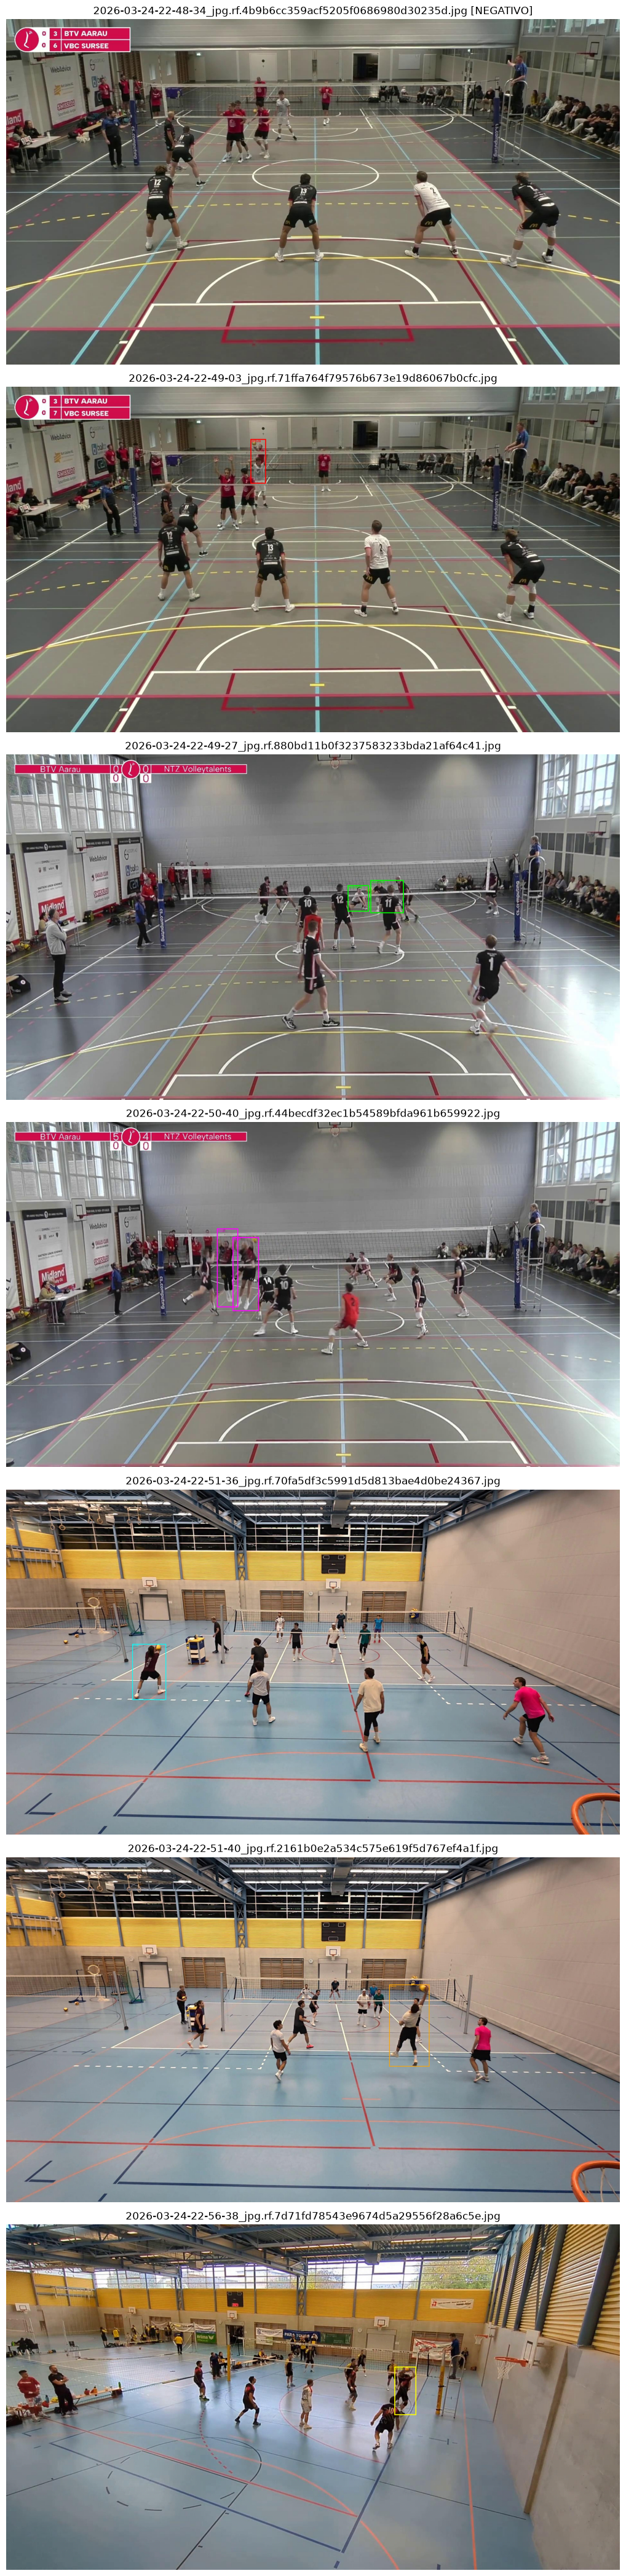

In [7]:
import matplotlib.pyplot as plt
train_records = [row for row in AUDIT['records'] if row['split'] == 'train']
examples = []
seen_classes = set()
negative_added = False
for record in train_records:
    rows = read_annotations(SOURCE_SPLITS['train'] / 'labels' / record['source_label'])
    class_ids = {row['target_id'] for row in rows if row['target_id'] is not None}
    if class_ids - seen_classes and len(seen_classes) < SAMPLE_COUNT:
        examples.append(record)
        seen_classes.update(class_ids)
    elif not class_ids and not negative_added:
        examples.append(record)
        negative_added = True
    if len(seen_classes) == 6 and negative_added:
        break
colors = ['red', 'lime', 'cyan', 'orange', 'magenta', 'yellow']
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 6 * len(examples)), squeeze=False)
for axis, record in zip(axes[:, 0], examples):
    image_path = DERIVED_DIR / 'train' / 'images' / record['derived_name']
    with Image.open(image_path) as opened:
        preview = opened.convert('RGB')
    draw = ImageDraw.Draw(preview)
    width, height = preview.size
    label_path = DERIVED_DIR / 'train' / 'labels' / (image_path.stem + '.txt')
    for line in label_path.read_text(encoding='utf-8').splitlines():
        cid, cx, cy, bw, bh = map(float, line.split())
        cid = int(cid)
        bounds = ((cx - bw / 2) * width, (cy - bh / 2) * height,
                  (cx + bw / 2) * width, (cy + bh / 2) * height)
        draw.rectangle(bounds, outline=colors[cid], width=3)
        draw.text((bounds[0], bounds[1]), TARGET_NAMES[cid], fill=colors[cid])
    axis.imshow(preview)
    axis.set_title(record['source_image'] + (' [NEGATIVO]' if record['negative'] else ''))
    axis.axis('off')
plt.tight_layout()
fig.savefig(SESSION_DIR / 'anteprima_train.png', dpi=100)
plt.show()

## 7. Training esplicito da YOLOv8m COCO

Impostare `RUN_TRAINING=True` e `ACKNOWLEDGE_SPLIT_LIMITATIONS=True` in configurazione soltanto dopo audit/anteprime. La cella si ferma altrimenti: Run All non avvia accidentalmente il training. Validation a ogni epoca, early stopping sulla validation e `best.pt` scelto dalla fitness di validation Ultralytics. Il test non entra nel training, nella scelta di epoche, iperparametri, soglie o checkpoint.

Il costruttore usa il **file locale verificato `yolov8m.pt`** (equivalente a `YOLO('yolov8m.pt')`, senza risoluzione/download impliciti). Il YAML `nc=6` ricostruisce la testa per sei classi: nessun `classes=` filter con testa a otto classi, nessun `single_cls`, nessun resume. Sono salvati `best.pt`, `last.pt`, `args.yaml`, CSV e curve della run.

In [8]:
if not RUN_TRAINING:
    raise RuntimeError('Training NON avviato. Dopo audit/anteprime impostare RUN_TRAINING=True nella configurazione.')
if not ACKNOWLEDGE_SPLIT_LIMITATIONS:
    raise RuntimeError('Leggere audit/leakage: impostare ACKNOWLEDGE_SPLIT_LIMITATIONS=True per accettare gli split scaricati, non indipendenti per partita.')
if not DERIVED_VERIFIED:
    raise RuntimeError('Preparazione/verifica dataset non completata.')
if sha256_file(RESOLVED_WEIGHTS) != WEIGHTS_PROVENANCE['sha256']:
    raise RuntimeError('Checkpoint COCO cambiato dopo il preflight.')
TRAIN_ARGS = {'data': str(DATA_YAML), 'epochs': EPOCHS, 'patience': PATIENCE, 'imgsz': IMAGE_SIZE,
              'batch': BATCH_SIZE, 'device': DEVICE, 'workers': WORKERS, 'seed': SEED,
              'project': str(SESSION_DIR), 'name': 'training', 'exist_ok': False,
              'pretrained': True, 'resume': False, 'single_cls': False, 'val': True,
              'save': True, 'plots': True, 'cache': False, 'amp': False}
(SESSION_DIR / 'configurazione_training.json').write_text(json.dumps(TRAIN_ARGS, indent=2), encoding='utf-8')
model = YOLO(str(RESOLVED_WEIGHTS))
train_results = model.train(**TRAIN_ARGS)
TRAIN_RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = TRAIN_RUN_DIR / 'weights' / 'best.pt'
LAST_WEIGHTS = TRAIN_RUN_DIR / 'weights' / 'last.pt'
if not BEST_WEIGHTS.is_file() or not LAST_WEIGHTS.is_file():
    raise FileNotFoundError('Training terminato senza best.pt/last.pt: controllare la run.')
if model.names != dict(enumerate(TARGET_NAMES)):
    raise RuntimeError(f'Testa/classi inattese dopo training: {model.names}')
print('Best (validation):', BEST_WEIGHTS)
print('Last:', LAST_WEIGHTS)

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\dataset_6classi\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, h

## 8. Validation del best e test finale separato

La validation descrive il checkpoint gia selezionato. Per il **test finale**, fissare le scelte usando solo train/val, poi impostare `RUN_FINAL_TEST=True`; il notebook non cerca iperparametri sul test. I parametri di valutazione sono predefiniti qui (`conf=0.001`, `iou=0.7`), identici su val/test. Precision/recall per classe sono quelli restituiti da Ultralytics sulla curva PR; AP50 e mAP50-95 sono metriche detection, non accuratezza di eventi scout. Ogni tabella contiene sempre sei righe; classi senza metriche disponibili sono NaN espliciti, non zero inventato.

Esporta metriche aggregate/per classe, CSV, confusion matrix numerica quando disponibile, grafici Ultralytics e nomi dei checkpoint. Nessuna etichetta di palla/Player viene inferita o usata in regole contestuali.

In [9]:
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError('Eseguire il training prima della valutazione.')
best_model = YOLO(str(BEST_WEIGHTS))
if best_model.names != dict(enumerate(TARGET_NAMES)):
    raise ValueError(f'Checkpoint non a sei classi: {best_model.names}')
EVAL_ARGS = {'data': str(DATA_YAML), 'imgsz': IMAGE_SIZE, 'batch': BATCH_SIZE,
             'device': DEVICE, 'workers': WORKERS, 'conf': 0.001, 'iou': 0.7,
             'plots': True, 'save_json': True, 'project': str(SESSION_DIR), 'exist_ok': False}
EVALUATIONS = {}

def evaluate_split(split):
    metrics = best_model.val(split=split, name=f'best_{split}', **EVAL_ARGS)
    save_dir = Path(metrics.save_dir)
    class_indices = [int(value) for value in metrics.box.ap_class_index]
    rows = []
    for cid, name in enumerate(TARGET_NAMES):
        row = {'class_id': cid, 'class_name': name,
               'ground_truth_boxes': next(s[name] for s in AUDIT['summary'] if s['split'] == split),
               'precision': math.nan, 'recall': math.nan, 'AP50': math.nan, 'mAP50_95': math.nan}
        if cid in class_indices:
            index = class_indices.index(cid)
            row.update(precision=float(metrics.box.p[index]), recall=float(metrics.box.r[index]),
                       AP50=float(metrics.box.ap50[index]), mAP50_95=float(metrics.box.ap[index]))
        else:
            warnings.warn(f'{split}: metriche non disponibili per {name}; esportate come NaN.')
        rows.append(row)
    table = pd.DataFrame(rows)
    table.to_csv(save_dir / 'metriche_per_classe.csv', index=False)
    aggregate = {str(key): float(value) for key, value in metrics.results_dict.items()}
    (save_dir / 'metriche_aggregate.json').write_text(json.dumps(aggregate, indent=2), encoding='utf-8')
    confusion = getattr(metrics, 'confusion_matrix', None)
    if confusion is not None and getattr(confusion, 'matrix', None) is not None:
        # Ultralytics: righe predicted, colonne true; ultima classe background.
        names = TARGET_NAMES + ['background']
        matrix = pd.DataFrame(confusion.matrix, index=names, columns=names)
        matrix.to_csv(save_dir / 'confusion_matrix_predicted_rows_true_columns.csv')
    else:
        warnings.warn('Matrice numerica non esposta dalla versione installata; verificare confusion_matrix.png della run.')
    EVALUATIONS[split] = {'directory': str(save_dir), 'aggregate': aggregate}
    display(table)
    print('Output valutazione:', save_dir)
    return metrics

validation_metrics = evaluate_split('val')
if RUN_FINAL_TEST:
    test_metrics = evaluate_split('test')
else:
    print('Test finale NON eseguito: attivare RUN_FINAL_TEST solo dopo aver fissato tutte le scelte su train/val.')

Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
Model summary (fused): 92 layers, 25,843,234 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 982.6±570.4 MB/s, size: 250.6 KB)
val: Scanning C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\dataset_6classi\val\labels.cache... 716 images, 22 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 716/716 300.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 90/90 6.1it/s 14.7s0.2s
                   all        716       1054      0.816      0.777      0.824      0.524
               battuta        102        102      0.942      0.958      0.978      0.679
             ricezione         88         88      0.733      0.779      0.821      0.598
                alzata        167        169      0.878      0.78

,class_id,class_name,ground_truth_boxes,precision,recall,AP50,mAP50_95
0,0,battuta,102,0.942153,0.958083,0.977667,0.679308
1,1,ricezione,88,0.732859,0.779387,0.820694,0.598444
2,2,alzata,169,0.877583,0.786982,0.887191,0.519246
3,3,attacco,214,0.865203,0.659856,0.822819,0.433474
4,4,muro,392,0.913385,0.914644,0.942343,0.571695
5,5,difesa,89,0.564805,0.561798,0.493893,0.340347


Output valutazione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\best_val
Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
Model summary (fused): 92 layers, 25,843,234 parameters, 0 gradients, 78.7 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 23.4±9.6 MB/s, size: 267.7 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\dataset_6classi\test\labels... 200 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 415.0it/s 0.5s.1s
val: New cache created: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\dataset_6classi\test\labels.cach

,class_id,class_name,ground_truth_boxes,precision,recall,AP50,mAP50_95
0,0,battuta,33,0.856383,1.000000,0.954240,0.685415
1,1,ricezione,37,0.699006,0.627797,0.722229,0.520059
2,2,alzata,48,0.843202,0.896278,0.909867,0.547897
3,3,attacco,50,0.886505,0.800000,0.886856,0.481202
4,4,muro,85,0.906647,0.914101,0.963702,0.569495
5,5,difesa,19,0.564249,0.578947,0.465886,0.312593


Output valutazione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\best_test


## 9. Artefatti e configurazione finale

La cartella sessione conserva audit, mapping manifest e provenienza; `training/weights` contiene best/last. Ultralytics salva CSV e curve; le valutazioni hanno tabelle a sei classi, JSON e confusion matrix. I risultati di test sono validi solo nei limiti degli split originali documentati. Questo notebook non esegue inferenza con regole palla-giocatori, non esporta un modello addestrato prima del training e non dichiara generalizzazione per partita.

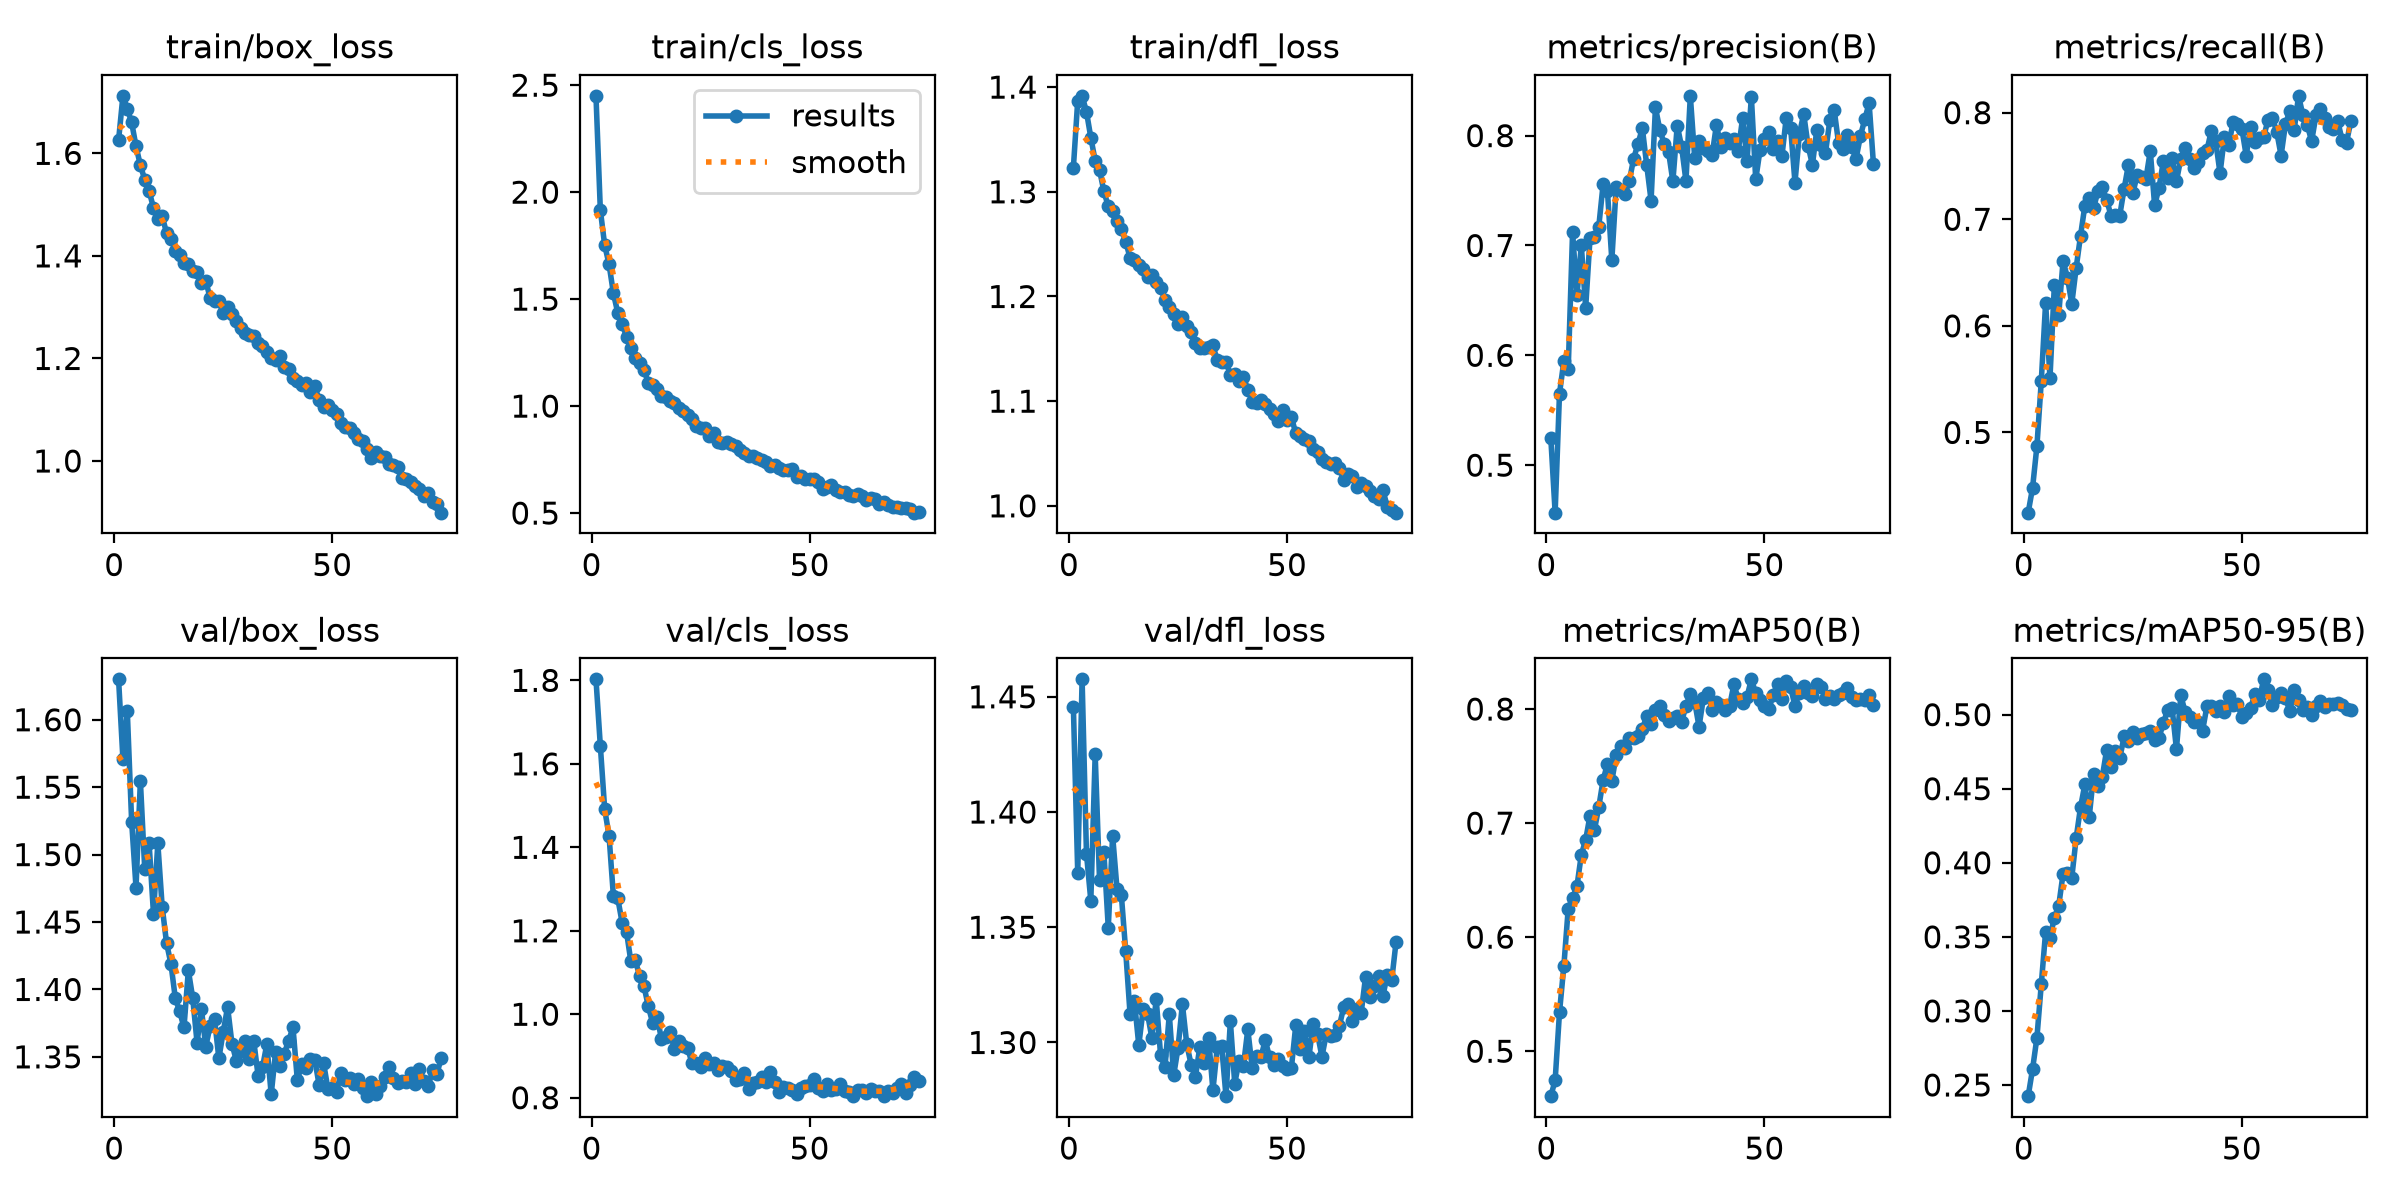

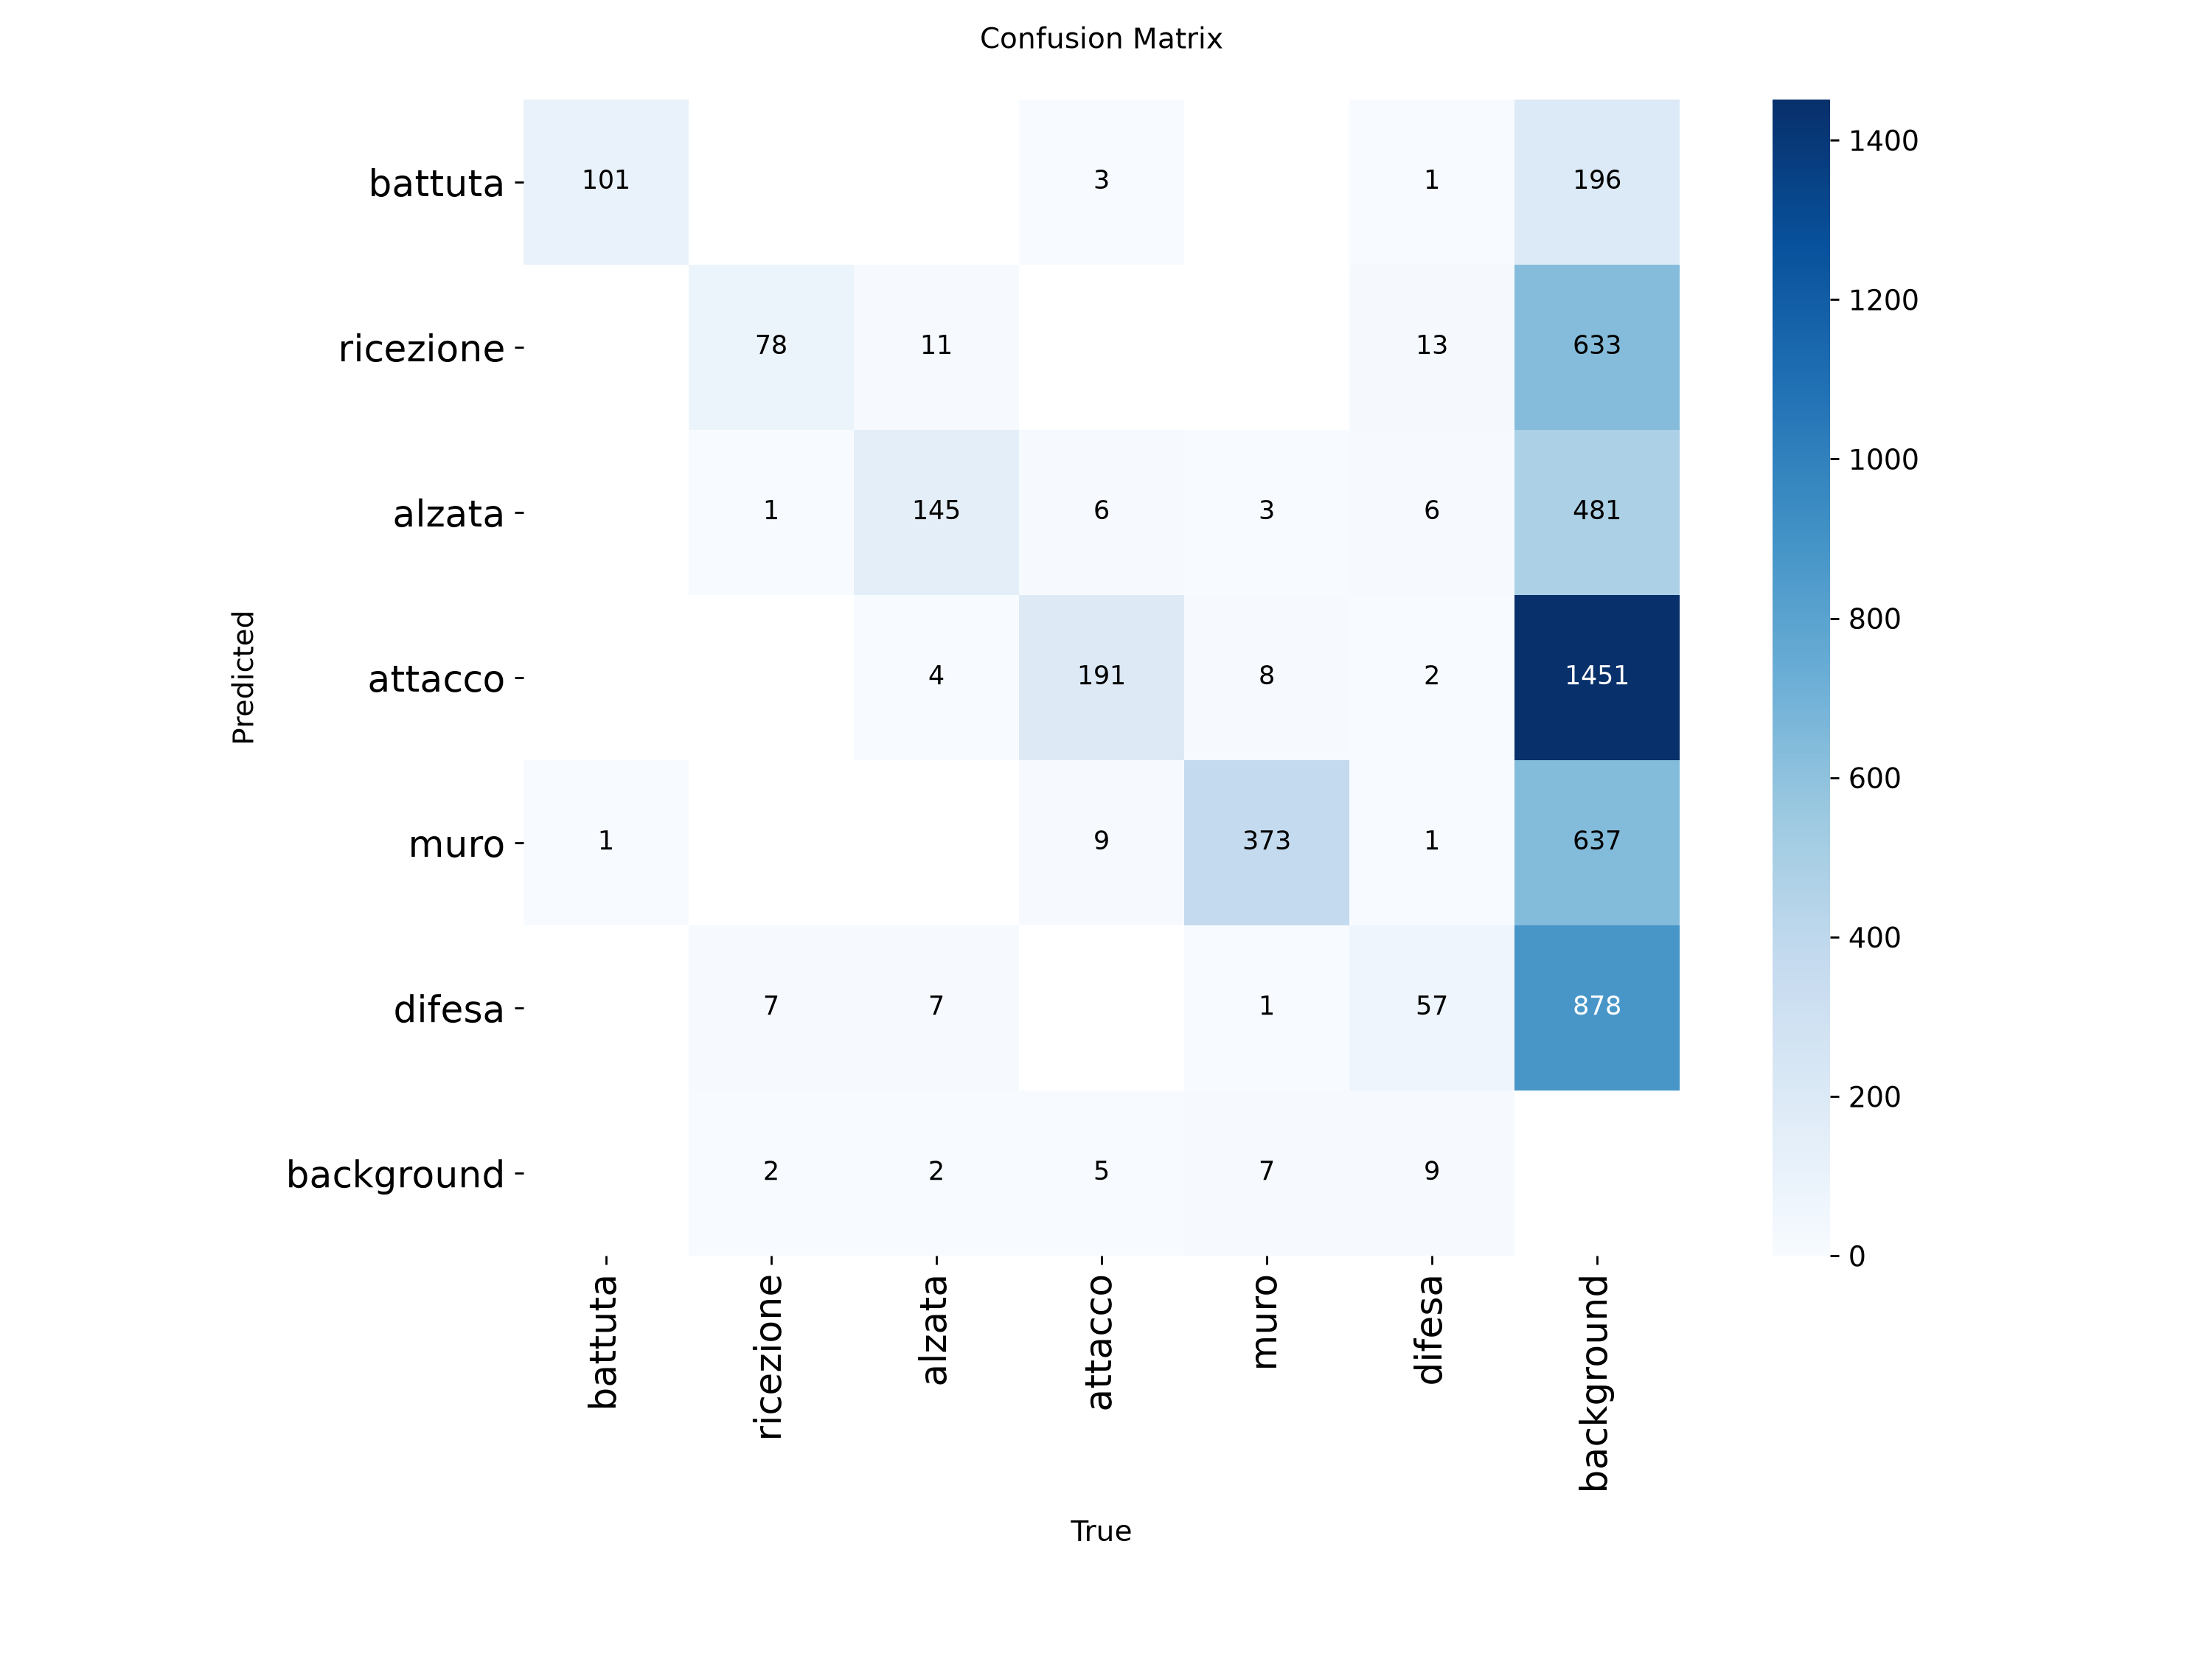

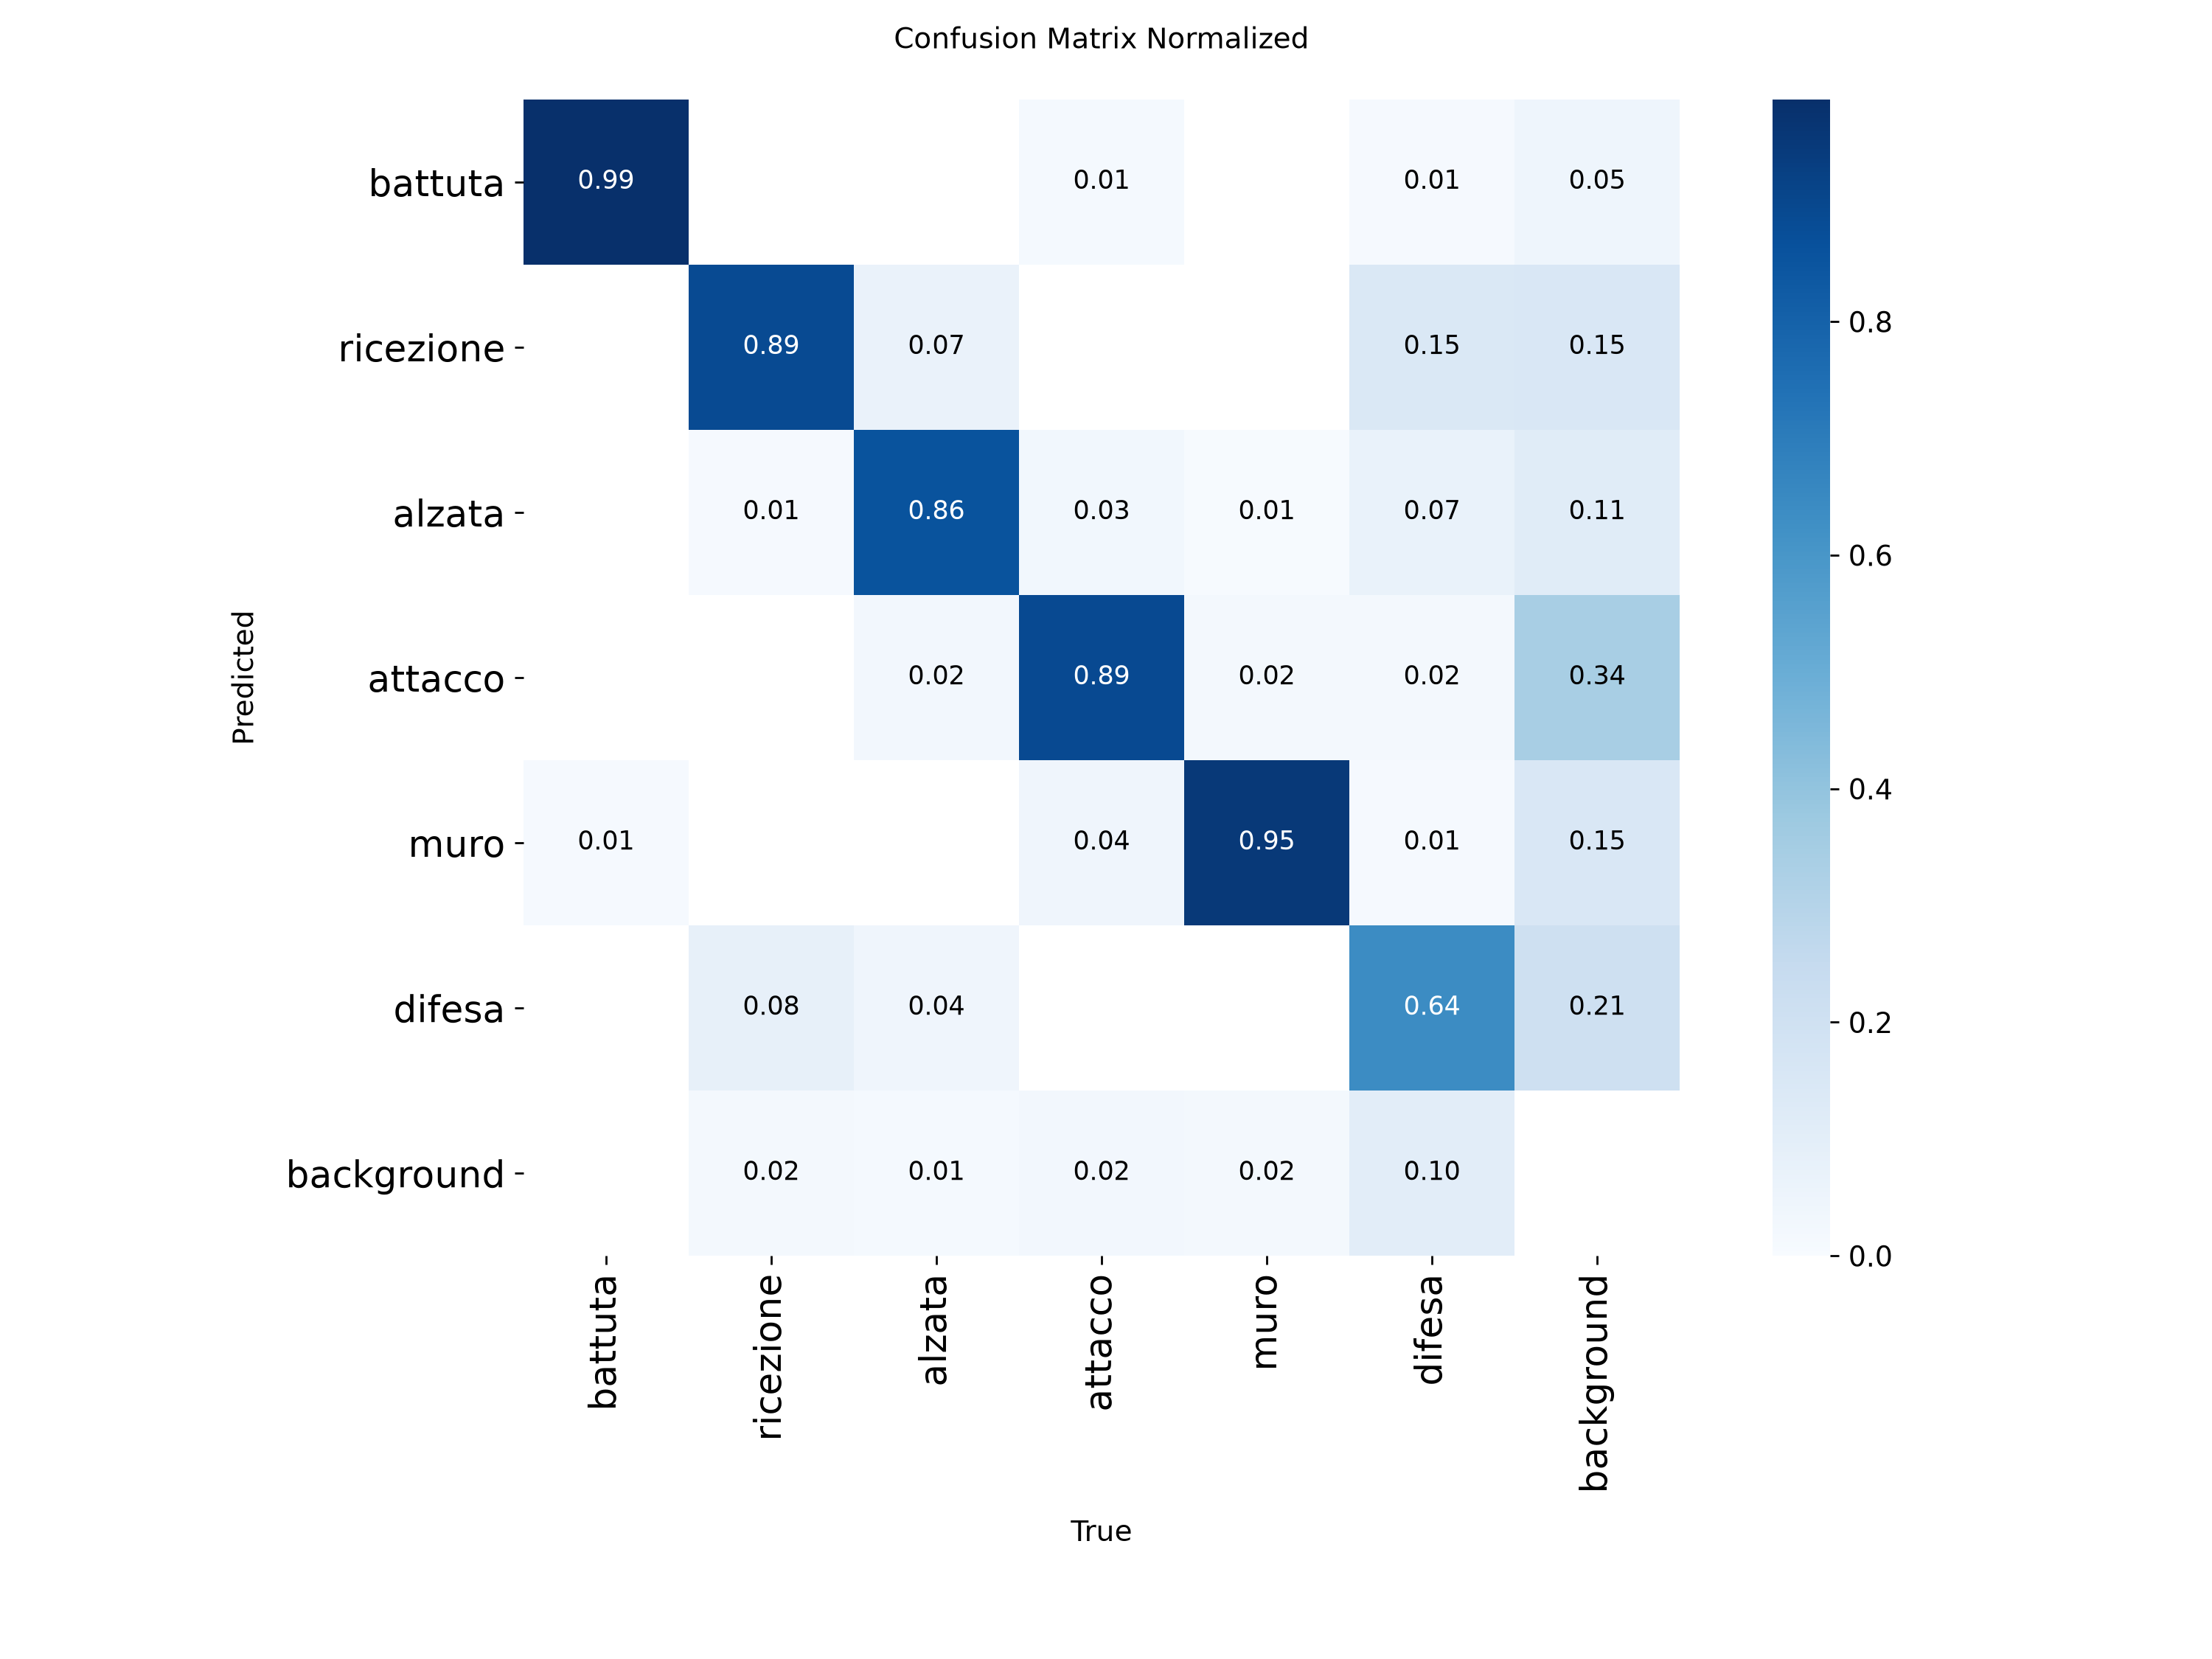

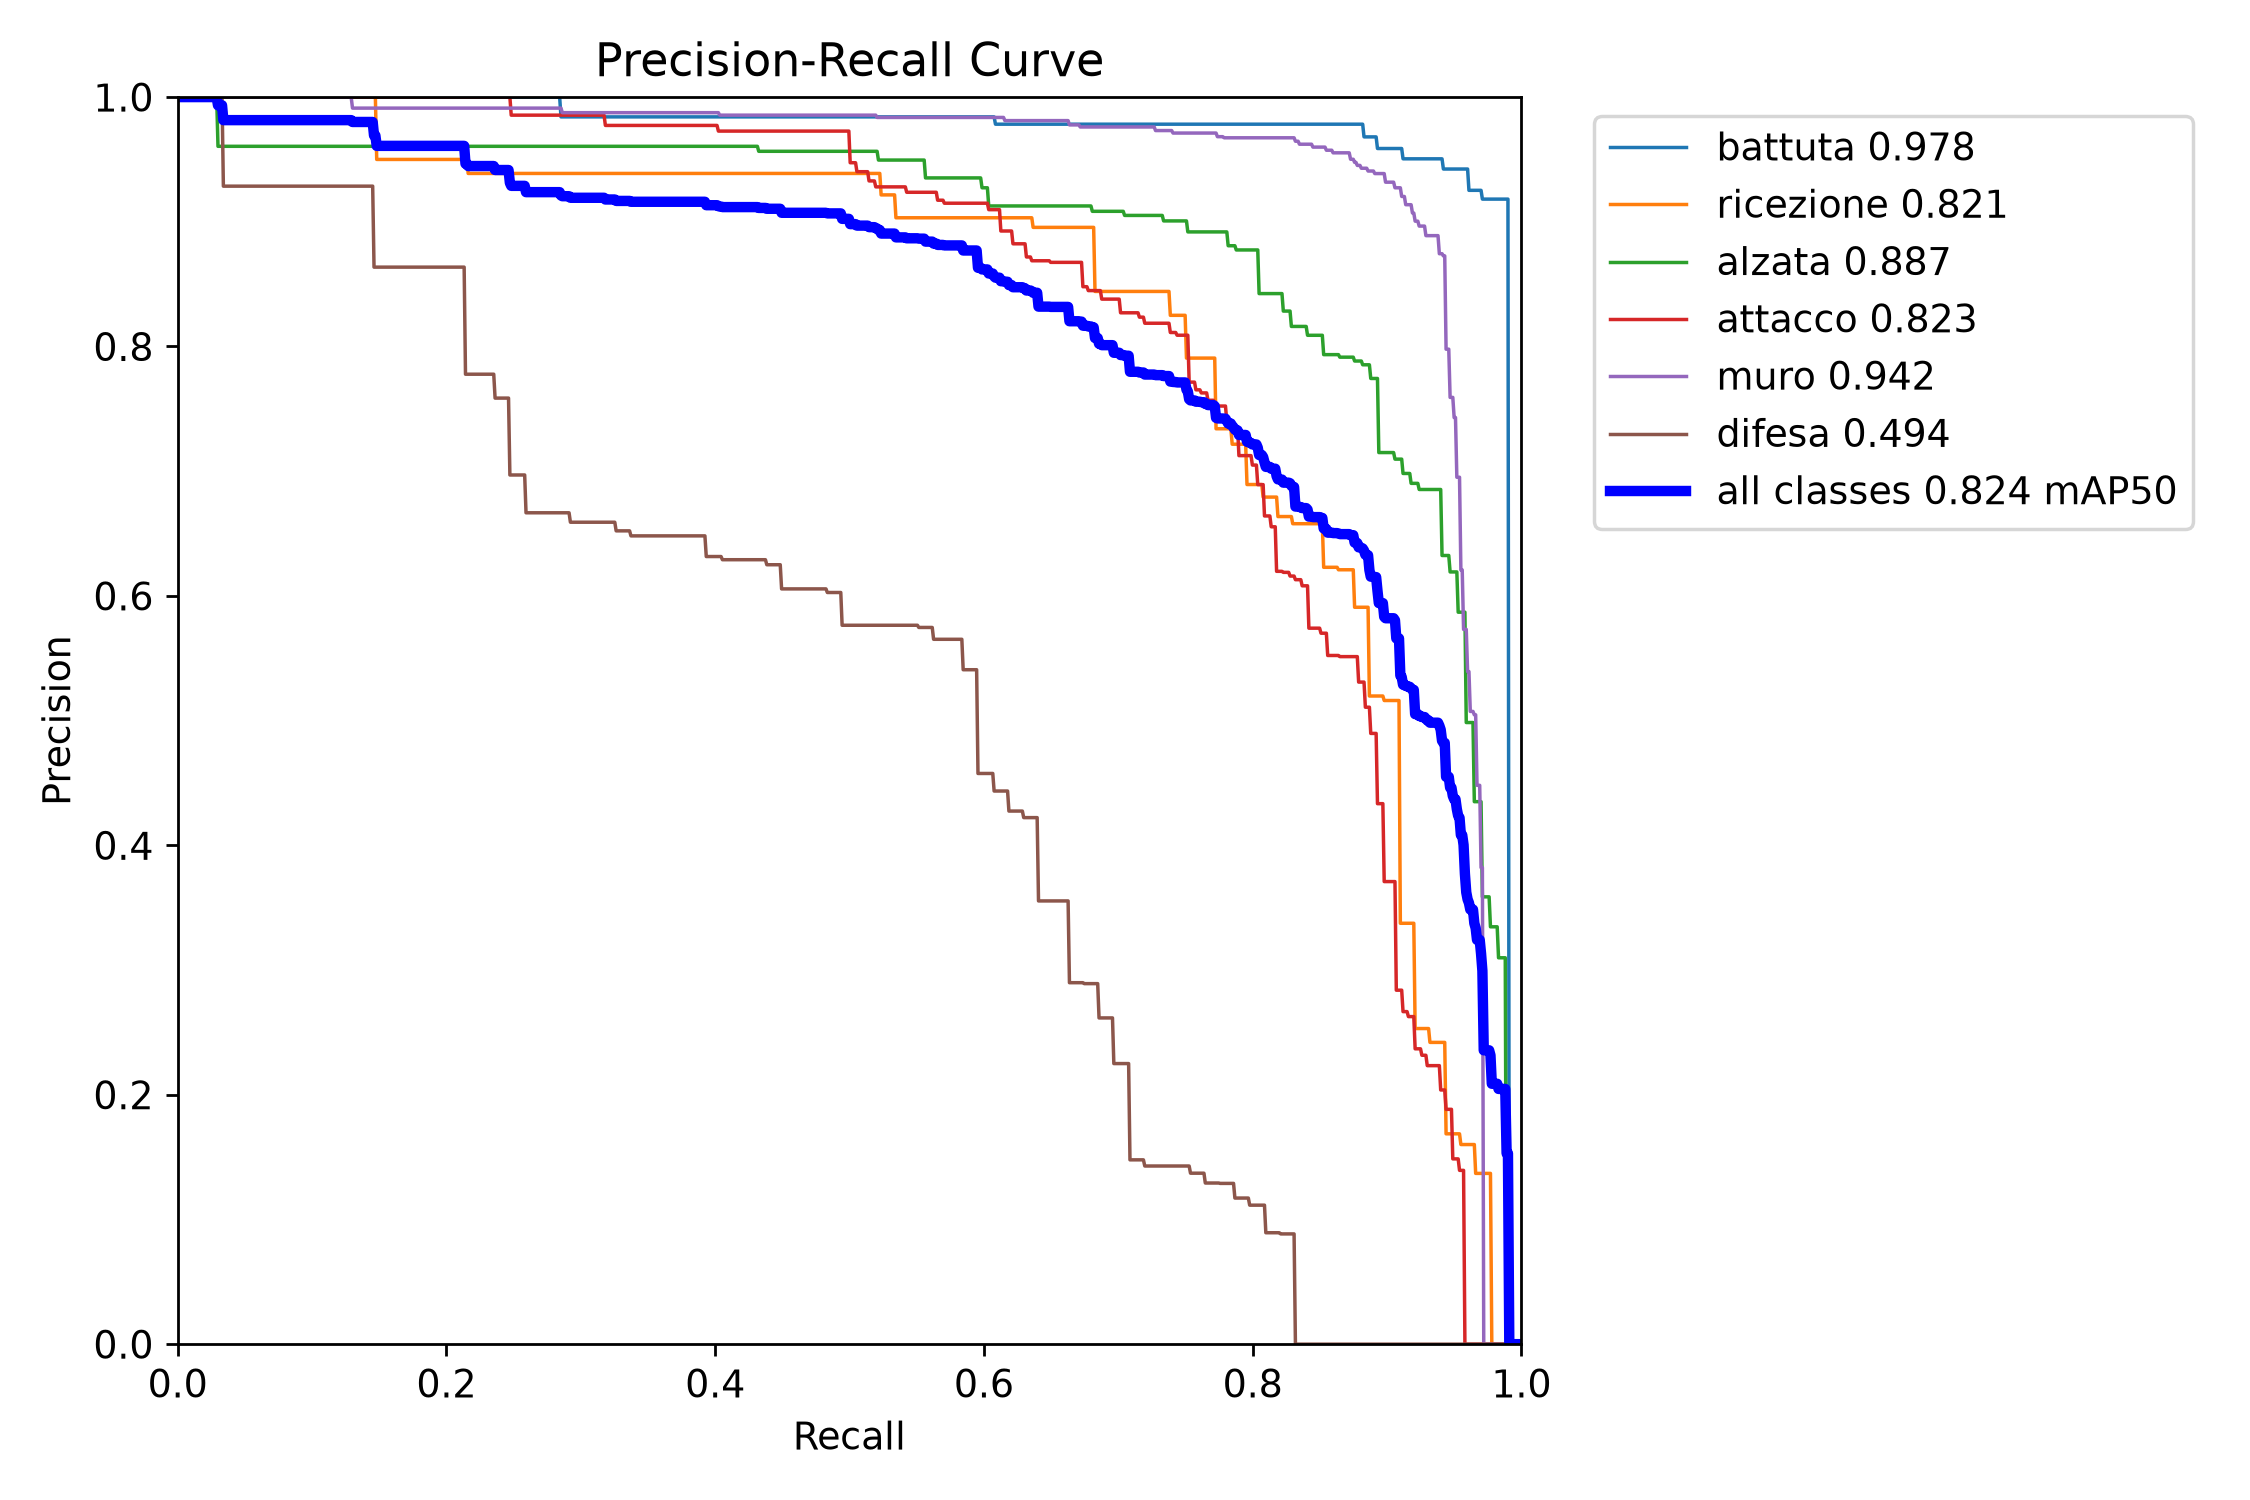

Grafico non generato da questa versione/configurazione: PR_curve.png


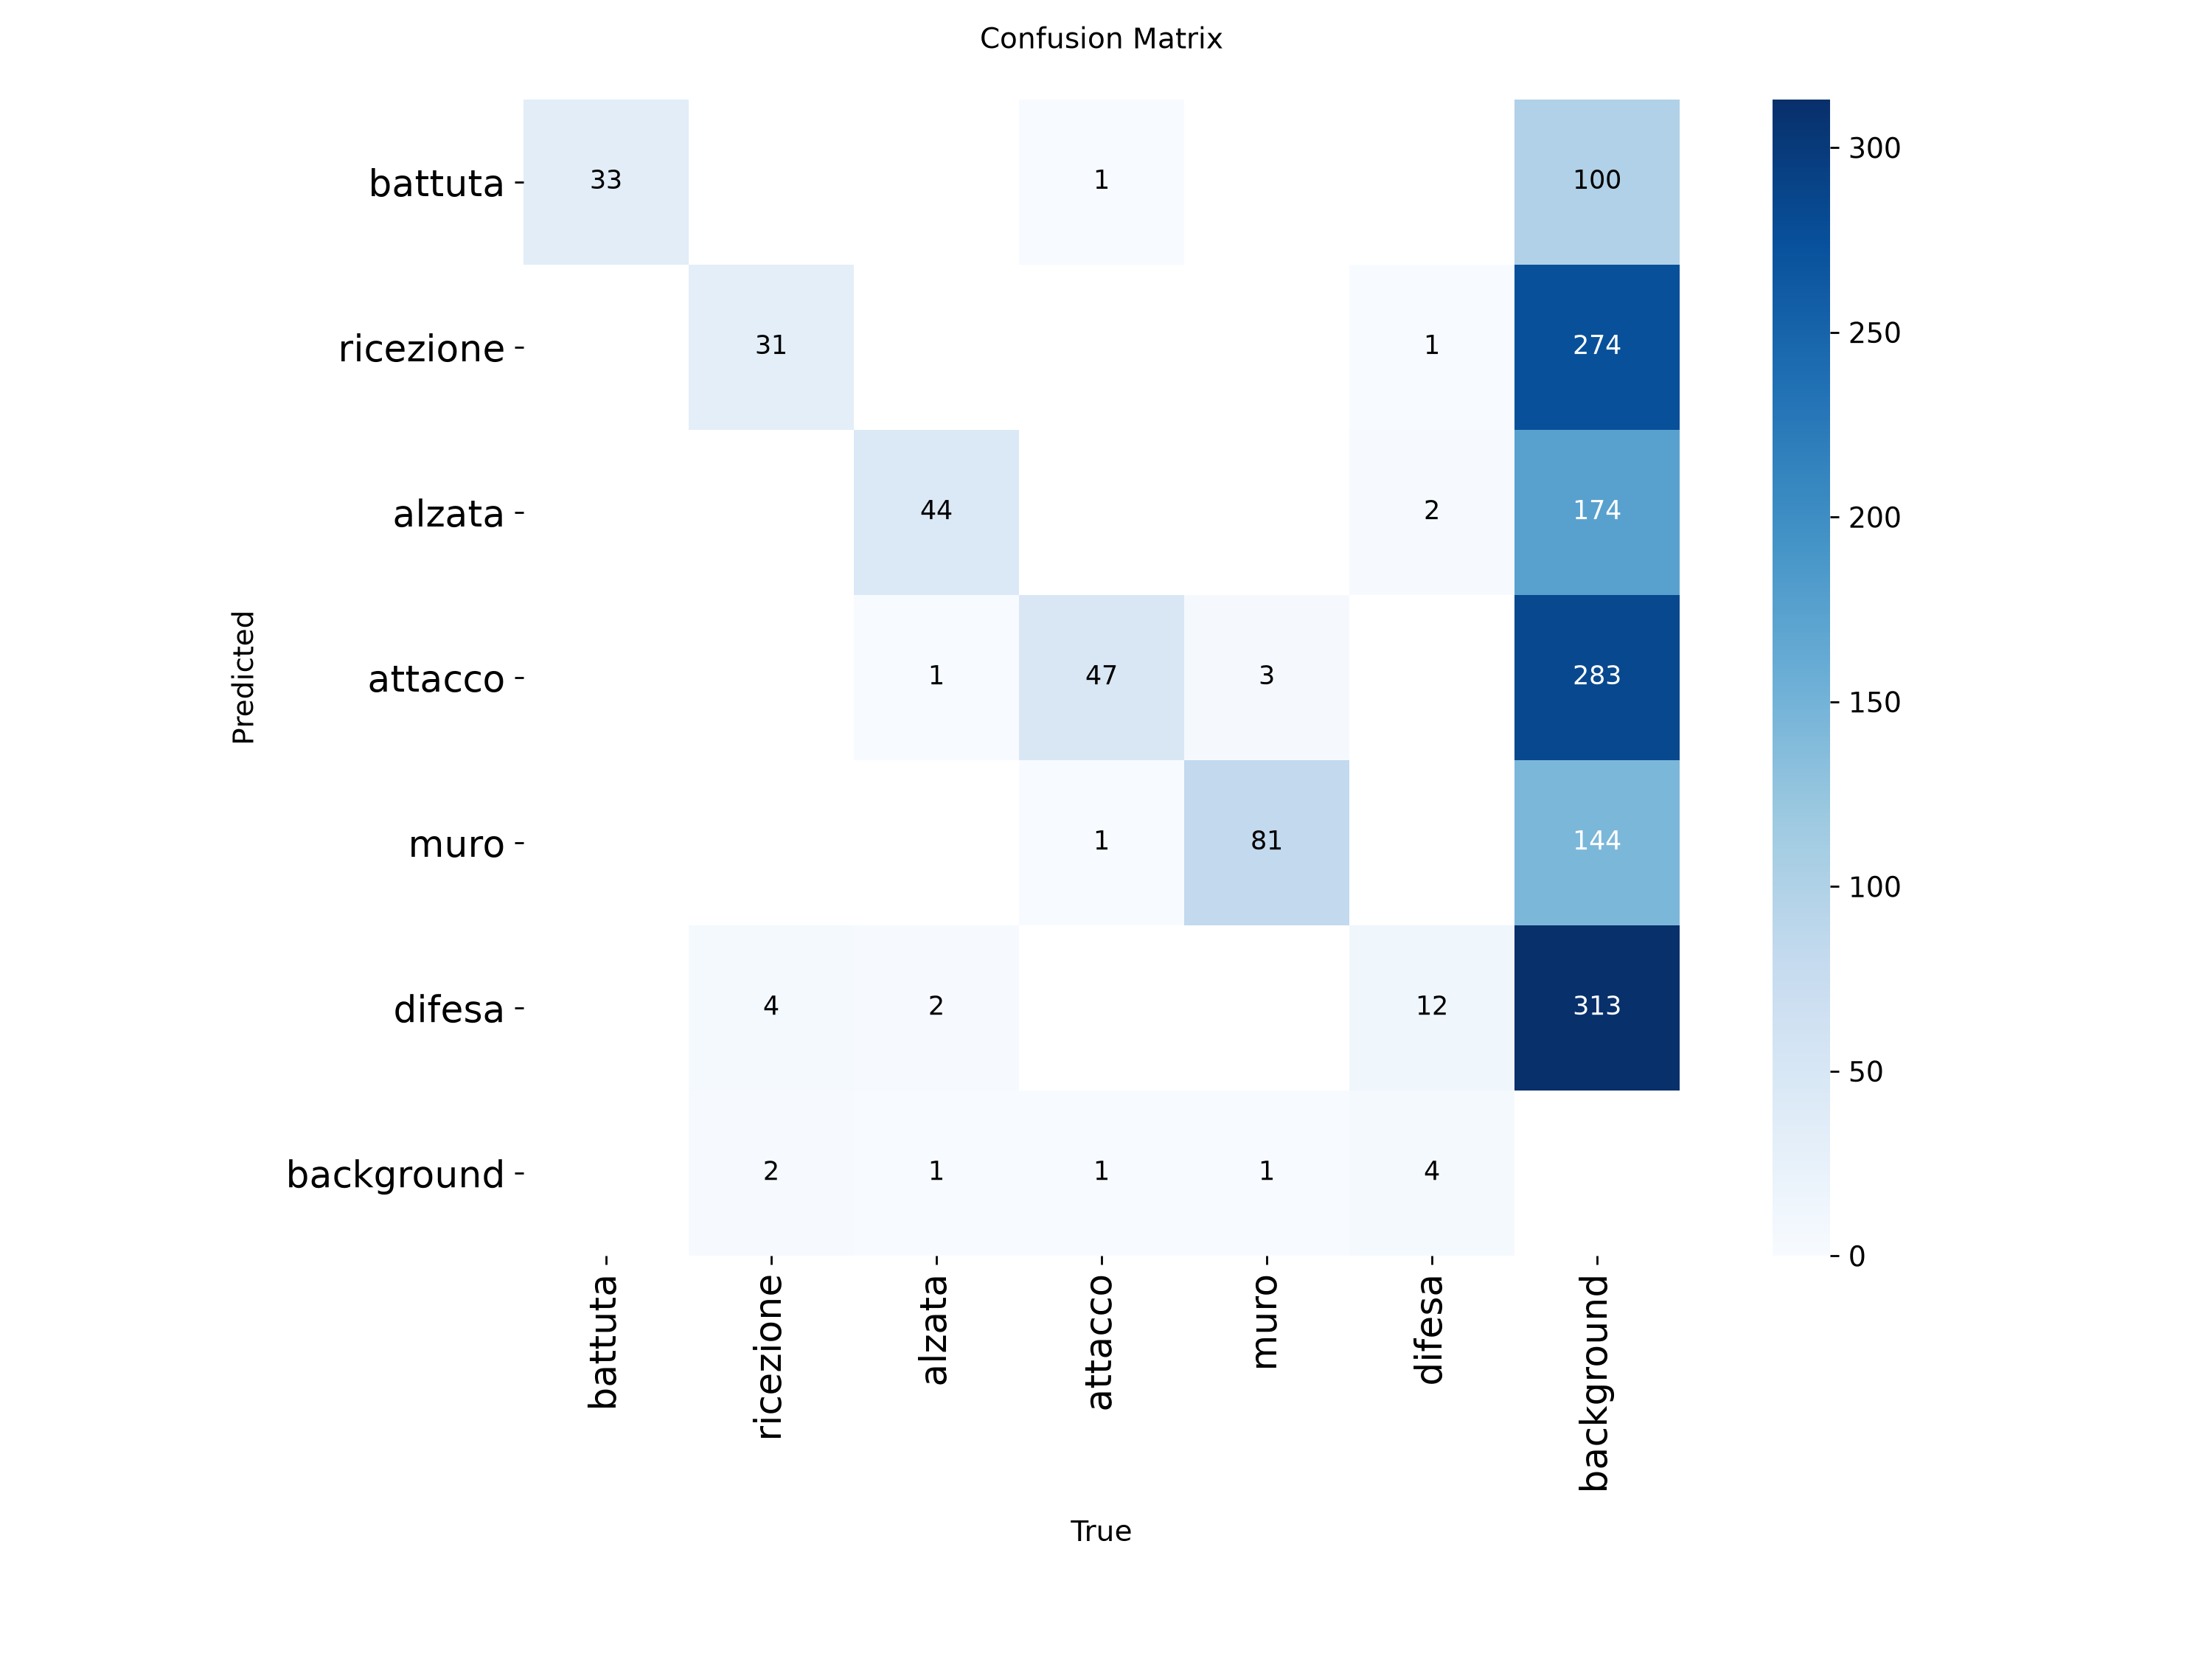

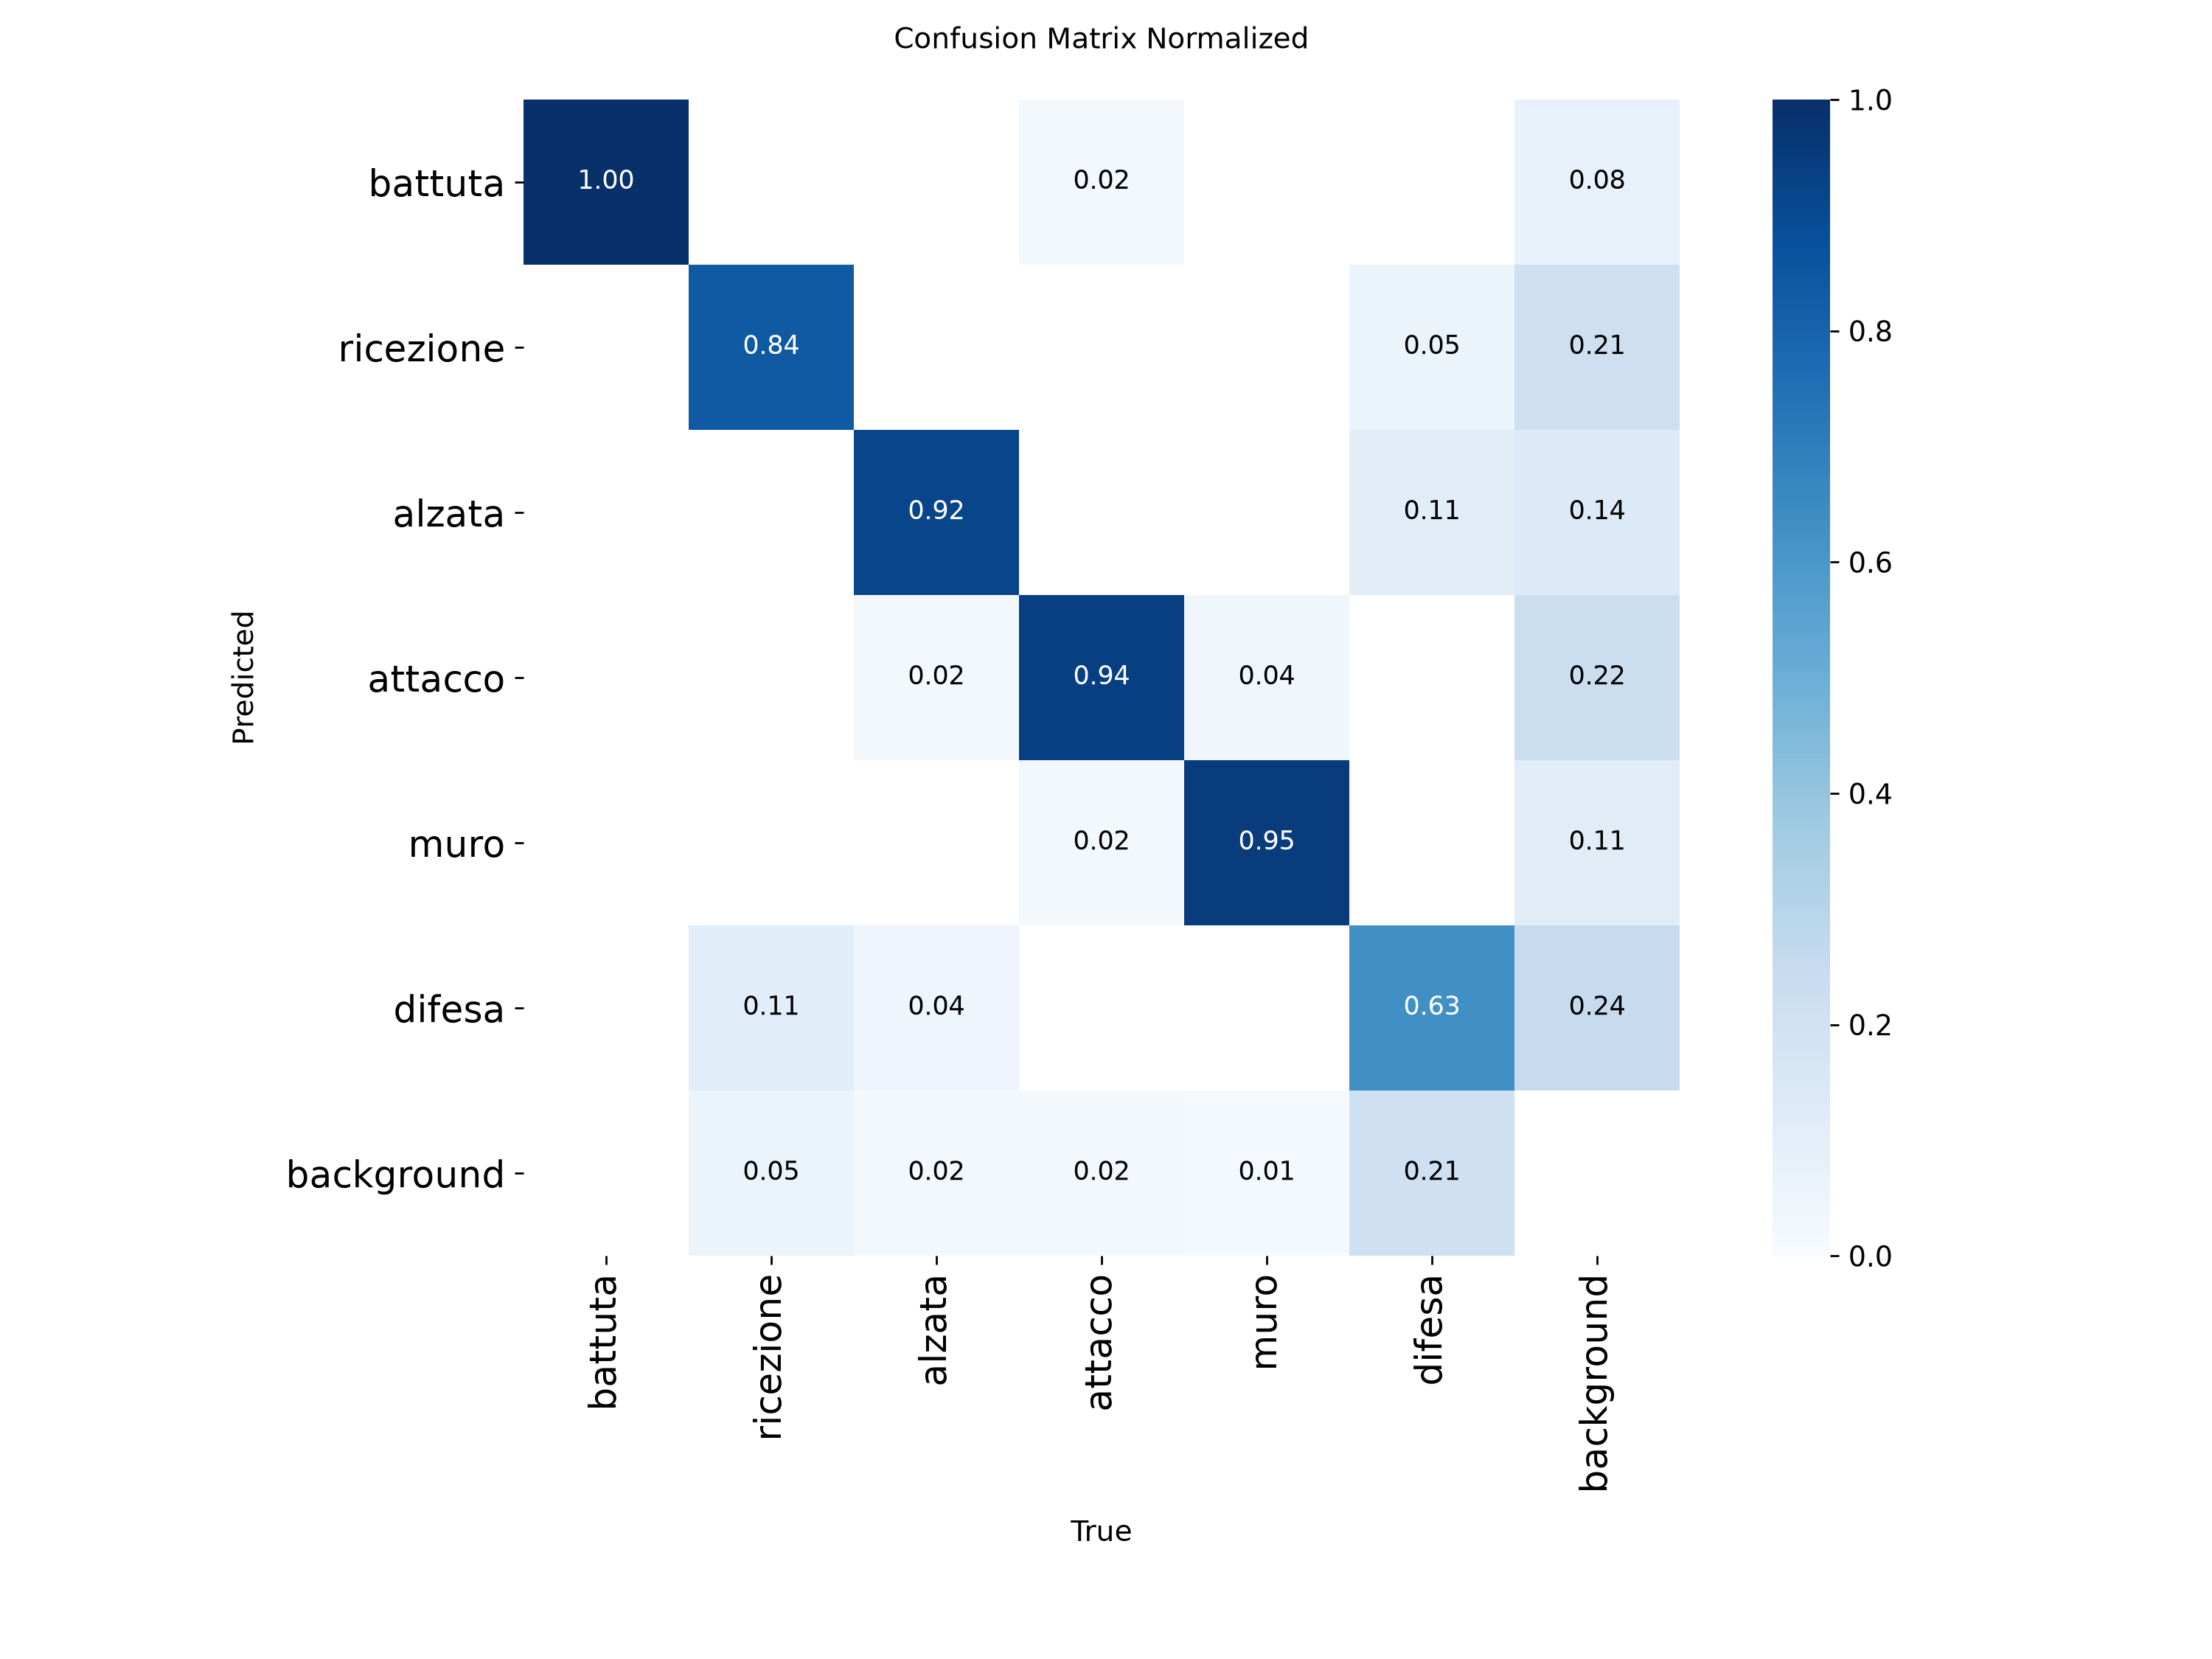

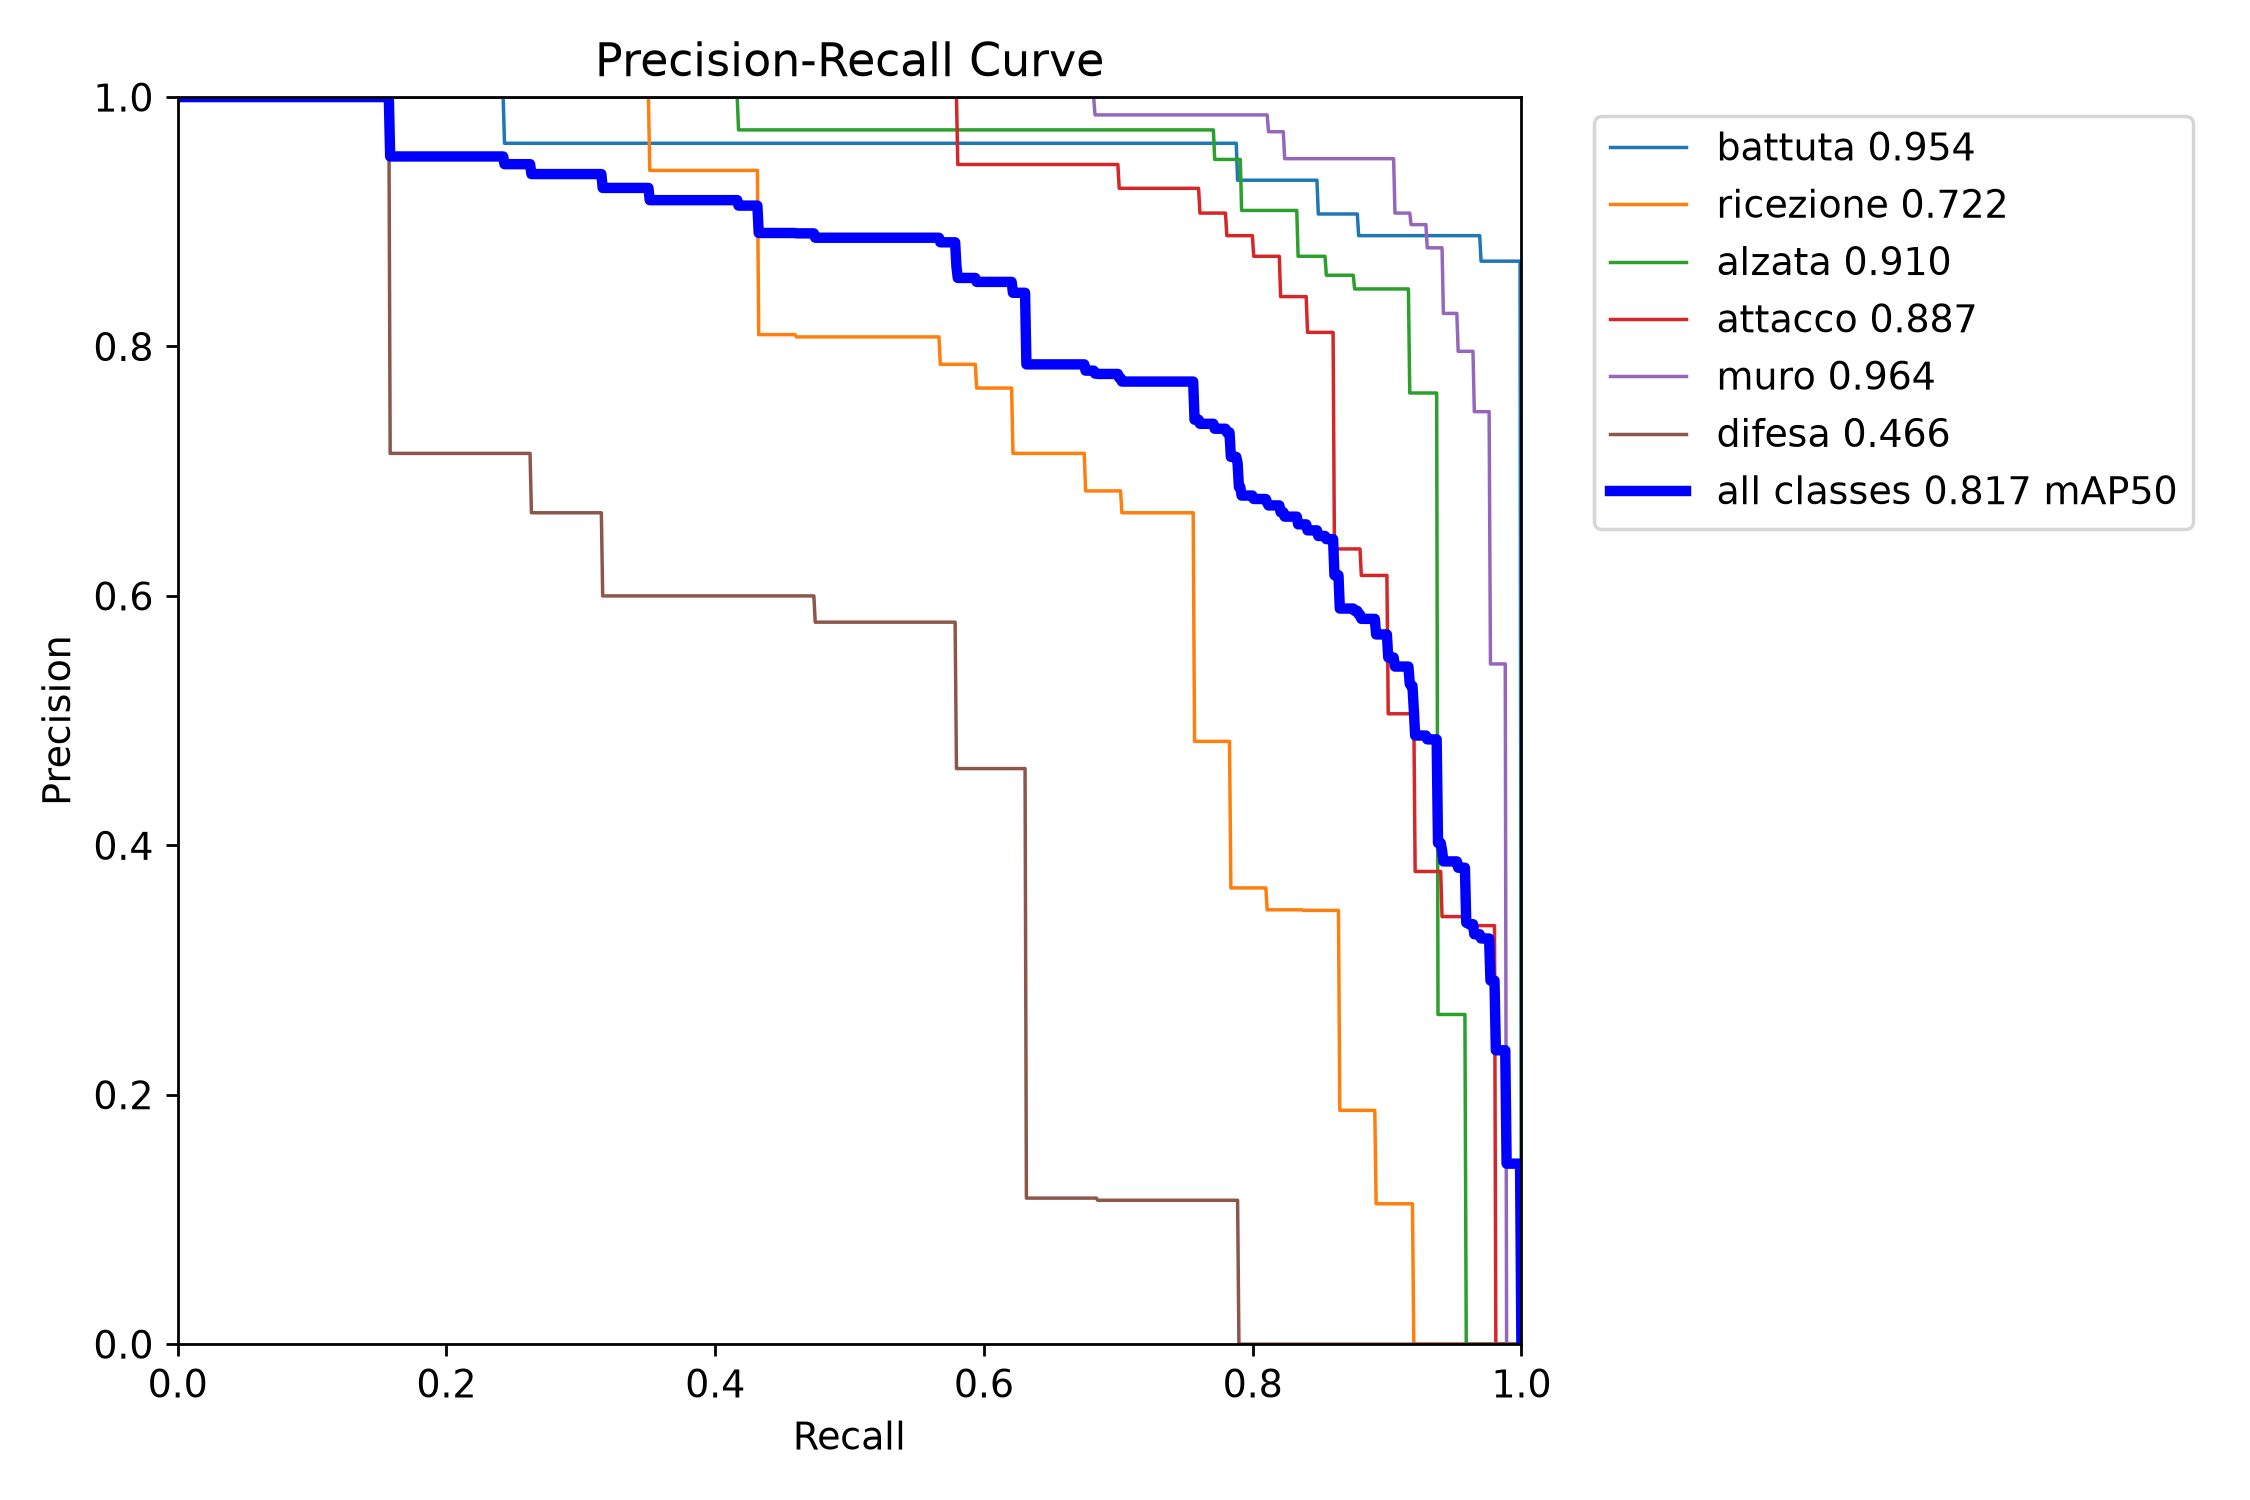

Grafico non generato da questa versione/configurazione: PR_curve.png
Artefatti sessione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1
Best: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\training\weights\best.pt 
Last: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\sei_gesti_dataset\20261120_223420_d3008fd1\training\weights\last.pt
Test finale eseguito: True


In [10]:
from IPython.display import display, Image as DisplayImage
final_config = {**PROVENANCE, 'training_args': TRAIN_ARGS, 'evaluation_args': EVAL_ARGS,
                'training_run_dir': str(TRAIN_RUN_DIR), 'best_weights': str(BEST_WEIGHTS),
                'last_weights': str(LAST_WEIGHTS), 'best_sha256': sha256_file(BEST_WEIGHTS),
                'last_sha256': sha256_file(LAST_WEIGHTS), 'evaluations': EVALUATIONS,
                'test_evaluated': 'test' in EVALUATIONS,
                'acknowledged_split_limitations': ACKNOWLEDGE_SPLIT_LIMITATIONS,
                'selection_policy': 'best.pt selected only by validation fitness'}
(SESSION_DIR / 'configurazione_finale.json').write_text(json.dumps(final_config, indent=2), encoding='utf-8')
plot_paths = [TRAIN_RUN_DIR / 'results.png']
for evaluation in EVALUATIONS.values():
    plot_paths.extend(Path(evaluation['directory']) / name for name in
                      ('confusion_matrix.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png', 'PR_curve.png'))
for plot_path in plot_paths:
    if plot_path.is_file():
        display(DisplayImage(filename=str(plot_path)))
    else:
        print('Grafico non generato da questa versione/configurazione:', plot_path.name)
print('Artefatti sessione:', SESSION_DIR)
print('Best:', BEST_WEIGHTS, '\nLast:', LAST_WEIGHTS)
print('Test finale eseguito:', 'test' in EVALUATIONS)